In [1]:
! pip install gwpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 37.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.4/322.4 kB 34.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.2/45.2 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.1/114.1 kB 14.4 MB/s eta 0:00:00


In [7]:
import os
# FIX: Force TF determinism — must be set before any TF imports or ops
os.environ['TF_DETERMINISTIC_OPS'] = '1'
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'

import argparse
import numpy as np
import tensorflow as tf
import time
import shutil
import zipfile
import joblib
import hashlib
import warnings
import json
from datetime import datetime
from dataclasses import dataclass
from scipy.signal import spectrogram
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.utils import class_weight, shuffle
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, accuracy_score,
    precision_score, recall_score, log_loss, brier_score_loss)
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import sys

from gwpy.timeseries import TimeSeries
from gwosc.datasets import event_gps

from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout,
    BatchNormalization, SpatialDropout2D, Add, Activation,
    Multiply, UpSampling2D, Concatenate, Resizing)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, Callback, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2
import tensorflow.keras.backend as K

warnings.filterwarnings("ignore")

# ─────────────────────────────────────────────────────────────────────────────
# RANDOM SEED CONTROL
# ─────────────────────────────────────────────────────────────────────────────
# FIX (reproducibility): a single RUN_SEED now drives every source of
# randomness in this notebook (numpy, python's random module, TensorFlow,
# the sklearn shuffle/split calls, and the event-list shuffle in
# train_model_pipeline, which previously used the *unseeded* global RNG
# state and was therefore not reproducible run-to-run).
#
# To check robustness to initialization, re-run the 'train' pipeline with
# RUN_SEED set to a few different integers (e.g. 0, 1, 2) and look at the
# spread of test-set metrics — see `run_multiseed_pipeline` near the bottom
# of the PIPELINES section, which automates exactly this and reports
# mean ± std across seeds.
RUN_SEED = 42

def set_global_seed(seed: int):
    """Seed every RNG this notebook touches. Call this before any data
    shuffling, splitting, model building, or training."""
    import random as _random
    _random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

set_global_seed(RUN_SEED)

# ── Embedded event lists ──────────────────────────────────────────────────────

TRAIN_EVENTS = [
    'GW200224_222234', 'GW190704_104834', 'GW231206_233901', '170720',
    'GW200220_124850', 'GW231127_165300', 'GW230922_020344', 'GW170729',
    'GW200208_222617', 'GW191222_033537', 'GW230911_195324', 'GW190424_180648',
    'GW170608', 'GW230708_230935', 'GW190514_065416', 'GW230820_212515',
    'GW230518_125908', 'GW230628_231200', 'GW200112_155838', 'GW190630_185205',
    'GW231026_130704', 'GW230702_162025', 'GW231114_043211', 'GW230721_222634',
    'GW231204_090648', 'GW230822_230337', 'GW190814', 'GW230805_034249',
    'GW231223_032836', 'GW230529_181500', 'GW230624_113103', '170630',
    'GW190728_064510', 'GW191105_143521', '170219', 'GW230717_102139',
    'GW231231_154016', 'GW230606_024545', 'GW230630_125806', 'GW231231_120147',
    'GW230601_224134', 'GW230630_234532', 'GW190707_083226', 'blind_injection',
    'GW190727_060333', 'GW190720_000836', 'GW231226_101520', 'GW230728_083628',
    'GW190412', 'GW230927_153832', 'GW231118_090602', 'GW190916_200658',
    'GW170817', 'GW191204_110529', 'GW190821_124821', 'GW231126_010928',
    'GW190425', 'GW230608_205047', 'GW200209_085452', 'GW231102_052214',
    'GW230823_142524', '200219_201407', 'GW250114_082203', '161202',
    'GW230924_124453', 'GW191216_213338', '191225_215715', 'GW200208_130117',
    '200214_224526', 'GW170814', 'GW230625_211655', 'GW190719_215514',
    'GW191204_171526', 'GW190711_030756', 'GW230831_134621', 'GW230817_212349',
    '151012.2', 'GW190602_175927', 'GW190421_213856', 'GW231008_142521',
    'GW231005_144455', 'GW230807_205045', 'GW200219_094415', 'GW190930_133541',
    'GW230723_084820', 'GW240105_151143', 'GW191215_223052', 'GW231206_010629',
    'GW200129_065458', 'GW230609_064958', 'GW230927_043729', 'GW190926_050336',
    'GW230904_152545', 'GW231118_005626', 'GW190512_180714', 'GW231118_071402',
    '170405', 'GW190521', 'GW231223_202619', 'GW200128_022011',
    'GW190731_140936', 'GW231020_142947', 'GW230806_204041', 'GW200202_154313',
    '191223_014159', 'GW231102_232433', 'GW230704_021211', 'GW190805_211137',
    'GW191113_071753', 'GW231230_170116', 'GW191126_115259', 'GW190517_055101',
    'GW230708_071859', 'GW190818_232544', 'GW230706_104333', '170412',
    'GW230919_215712', 'GW231001_140220', 'GW230920_064709', 'GW231110_040320',
    'GW230830_064744', 'GW190814_192009', 'GW230928_215827', 'GW200302_015811',
    'GRB051103', 'GW191230_180458', 'GW231120_022103', 'GW230920_071124',
    'GW230531_141100', 'GW240109_050431', 'GW230914_111401', 'GW231029_111508',
    'GW190701_203306', 'GW200220_061928', 'GW191219_163120', 'GW191109_010717',
    'GW170809', 'GW231104_133418', 'GW200115_042309', 'GW230902_122814',
    'GW241011_233834', 'GW230825_041334', 'GW231129_081745', 'GW231028_153006',
    '151116', 'GW230609_010824', 'GW190426_190642', 'GW190920_113516',
    'GW190828_065509', 'GW190924_021846', 'GW190910_012619', 'GW190413_134308',
    'GW231221_135041', 'GW230729_082317', 'GW230630_070659', 'GW190910_112807',
    'GW190828_063405', 'GW231014_040532', 'GW230627_015337', 'GW190519_153544',
    'GW230726_002940', 'GW200210_092254', 'GW230803_033412', 'GW170104',
    'GW190803_022701', 'GW231013_135504', 'GW231123_135430', '170208',
    'GW170823', 'GW230904_051013', 'GW200201_203549', 'GW230712_090405',
    'GW230624_214944', 'GW190917_114630', 'GW230814_061920', 'GW151226',
    'GW200216_220804', 'GW190426_152155', 'GW230925_143957', 'GW190620_030421',
    'GW190925_232845', 'GW190725_174728', 'GW230709_063445', 'GW231018_233037',
    '170423', 'GW230704_212616', 'GW200225_060421', '200114_020818',
    'GW190413_052954', 'GW191103_012549', '161217', 'GW230707_124047',
    'GW200306_093714', 'GW230605_065343', 'GW240107_013215', 'GW170818',
    'GW200322_091133'
]

TEST_EVENTS = [
    'GW230618_102550', 'GW231224_024321', 'GW190527_092055', 'GW230731_215307',
    'GW230922_040658', 'GW230811_032116', 'GW231113_150041', '190924_232654',
    'GW230603_174756', 'GW231213_111417', 'GW230902_172430', 'GW231223_075055',
    'GW190929_012149', 'GW230709_122727', 'GW190707_093326', '151008',
    'GW190909_114149', 'GW230702_185453', 'GW190531_023648', 'GW190706_222641',
    'GW230819_171910', 'GW231102_071736', 'GW190906_054335', 'GW230615_160825',
    'GW231002_143916', 'GW241110_124123', 'GW200311_103121', 'GW231004_232346',
    'GW230814_230901', '170705', 'GW230708_053705', 'GW230723_101834',
    'GW150914', 'GW230824_033047', 'GW190403_051519', 'GW200105_162426',
    'GW191129_134029', 'GW190521_074359', 'GW230831_015414', 'GW200316_215756',
    'GW230824_135331', 'GW200311_115853', 'GW190503_185404', 'GW230606_004305',
    'GW231113_200417', 'GW231005_091549', 'GW151012', '170616',
    'GW190513_205428', '200121_031748', 'GW231113_122623', 'GW200308_173609',
    'GW190915_235702', 'GW191118_212859', 'GW230902_224555', 'GW231119_075248',
    'GW240104_164932', 'GW231220_173406', 'GW190718_160159', 'GW231206_233134',
    'GW191127_050227', 'GW190408_181802', 'GW231108_125142', 'GW190708_232457',
    'GW230930_110730', 'GW231005_021030'
]

@dataclass
class PipelineConfig:
    SEQ_LEN: int = 1024
    SAMPLE_RATE: int = 4096
    WINDOW_SIZE: int = 128
    STRIDE: int = 64

    IMG_HEIGHT: int = 65
    IMG_WIDTH: int = 69
    BATCH_SIZE: int = 64
    EPOCHS: int = 20

    BANDPASS_LOW: int = 30
    BANDPASS_HIGH: int = 400
    INFERENCE_THRESHOLD: float = 0.5

    SCALER_PATH: str = 'scaler.gz'
    CLASSIFIER_PATH: str = 'classifier_model.h5'
    EXPLAINER_PATH: str = 'explainer_model.h5'
    CALIBRATOR_PATH: str = 'calibrator.gz'
    GRAPH_DIR: str = 'generated_graphs'
    CACHE_DIR: str = 'data_cache'

CFG = PipelineConfig()

gpus = tf.config.list_physical_devices('GPU')
if len(gpus) > 0:
    try:
        tf.config.experimental.set_memory_growth(gpus[0], True)
        print(f"Running on GPU: {gpus[0]}")
    except RuntimeError as e:
        print(f"GPU already initialized: {e}")
else:
    print("Running on CPU")


# ─────────────────────────────────────────────────────────────────────────────
# LOSS / AUGMENTATION & METRICS
# ─────────────────────────────────────────────────────────────────────────────

def focal_loss(gamma=2., alpha=.75):
    # Note: If FAR remains stubbornly high, lowering 'alpha' (e.g., to 0.25)
    # during training can help penalize false positives more aggressively.
    def focal_loss_fixed(y_true, y_pred):
        pt_1 = tf.where(tf.equal(y_true, 1), y_pred, tf.ones_like(y_pred))
        pt_0 = tf.where(tf.equal(y_true, 0), y_pred, tf.zeros_like(y_pred))
        return -K.mean(alpha * K.pow(1. - pt_1, gamma) * K.log(pt_1 + K.epsilon())) - \
               K.mean((1 - alpha) * K.pow(pt_0, gamma) * K.log(1. - pt_0 + K.epsilon()))
    return focal_loss_fixed


class TrueLogLoss(tf.keras.metrics.Metric):
    """
    A custom metric to track Log Loss (BCE) perfectly during training.
    By intentionally ignoring 'sample_weight' applied by class_weight, this
    prevents Keras from artificially inflating the graph up to 60-70!
    """
    def __init__(self, name='log_loss', **kwargs):
        super(TrueLogLoss, self).__init__(name=name, **kwargs)
        self.total_bce = self.add_weight(name='total_bce', initializer='zeros')
        self.count = self.add_weight(name='count', initializer='zeros')

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_true = tf.cast(y_true, tf.float32)
        y_pred = tf.cast(y_pred, tf.float32)

        # Clip to prevent log(0) and safely keep metric stable
        y_pred = tf.clip_by_value(y_pred, K.epsilon(), 1.0 - K.epsilon())

        bce = -(y_true * tf.math.log(y_pred) + (1.0 - y_true) * tf.math.log(1.0 - y_pred))

        self.count.assign_add(tf.cast(tf.shape(y_true)[0], tf.float32))
        self.total_bce.assign_add(tf.reduce_sum(bce))

    def result(self):
        return self.total_bce / (self.count + K.epsilon())

    def reset_state(self):
        self.total_bce.assign(0.0)
        self.count.assign(0.0)

    def reset_states(self):
        self.reset_state()


class EarlyStoppingOnTestAUC(Callback):
    """
    Evaluates on a fixed test set every epoch and stops when test AUC
    has not improved for `patience` epochs. Restores the best weights.

    Args:
        test_data:   tuple (X_test, y_test) or a tf.data.Dataset
        patience:    epochs to wait after last improvement (default 7)
        min_delta:   minimum change to count as improvement (default 1e-4)
        restore_best_weights: restore weights from best epoch (default True)
        verbose:     0 = silent, 1 = print on stop (default 1)
    """

    def __init__(
        self,
        test_data,
        patience: int = 7,
        min_delta: float = 1e-4,
        restore_best_weights: bool = True,
        verbose: int = 1,
        ema_alpha: float = 0.4,
    ):
        super().__init__()
        self.test_data = test_data
        self.patience = patience
        self.min_delta = min_delta
        self.restore_best_weights = restore_best_weights
        self.verbose = verbose
        self.ema_alpha = ema_alpha

        self._best_auc = -np.inf
        self._wait = 0
        self._best_epoch = 0
        self._best_weights = None

        # history for plotting
        self.test_auc_history = []
        self.test_log_loss_history = []
        self.test_loss_history = []  # Tracks raw model loss (e.g., Focal Loss)
        self._ema_log_loss = None          # running EMA value

    # ── per-epoch evaluation ──────────────────────────────────────────────────

    def on_epoch_end(self, epoch, logs=None):
        results = self.model.evaluate(
            *self.test_data if isinstance(self.test_data, tuple) else [self.test_data],
            verbose=0,
            return_dict=True,
        )

        test_auc      = results.get("auc", results.get("val_auc", 0.0))
        raw_log_loss  = results.get("log_loss", results.get("val_log_loss", 0.0))
        raw_loss      = results.get("loss", results.get("val_loss", 0.0))

        # ── EMA smoothing for log loss (same α as train) ──────────────────────
        if self._ema_log_loss is None:
            self._ema_log_loss = raw_log_loss
        else:
            self._ema_log_loss = (
                self.ema_alpha * raw_log_loss
                + (1 - self.ema_alpha) * self._ema_log_loss
            )

        self.test_auc_history.append(test_auc)
        self.test_log_loss_history.append(self._ema_log_loss)
        self.test_loss_history.append(raw_loss)

        print(f"  — Test Loss: {raw_loss:.4f} | "
              f"Test AUC: {test_auc:.4f} | "
              f"Test LogLoss (raw): {raw_log_loss:.4f} | "
              f"Test LogLoss (EMA): {self._ema_log_loss:.4f}")

        # ── early-stopping logic on raw test AUC ─────────────────────────────
        if test_auc > self._best_auc + self.min_delta:
            self._best_auc     = test_auc
            self._best_epoch   = epoch
            self._wait         = 0
            if self.restore_best_weights:
                self._best_weights = self.model.get_weights()
        else:
            self._wait += 1
            if self._wait >= self.patience:
                self.model.stop_training = True
                if self.verbose:
                    print(
                        f"\nEarly stopping at epoch {epoch + 1}. "
                        f"Best test AUC {self._best_auc:.4f} at epoch "
                        f"{self._best_epoch + 1}."
                    )

    def on_train_end(self, logs=None):
        if self.restore_best_weights and self._best_weights is not None:
            self.model.set_weights(self._best_weights)
            if self.verbose:
                print(f"\nTraining completed. Restored best weights from epoch {self._best_epoch + 1}.")


def spec_augment(spec, max_time_mask=8, max_freq_mask=8):
    aug = spec.copy()
    f, t = spec.shape
    fw = np.random.randint(0, max_freq_mask)
    fs = np.random.randint(0, f - fw)
    aug[fs:fs + fw, :] = 0
    tw = np.random.randint(0, max_time_mask)
    ts = np.random.randint(0, t - tw)
    aug[:, ts:ts + tw] = 0
    return aug

# ─────────────────────────────────────────────────────────────────────────────
# DATA FETCHING (Kept exclusively for 'explain' pipeline)
# ─────────────────────────────────────────────────────────────────────────────

def fetch_and_condition_strain(start_time, end_time, detector):
    try:
        print(f"Downloading {detector} [{start_time:.2f} .. {end_time:.2f}]...", end=' ', flush=True)
        strain = TimeSeries.fetch_open_data(detector, start_time, end_time,
                                            sample_rate=CFG.SAMPLE_RATE,
                                            cache=True, verbose=False)
        print("OK")
        strain = strain.whiten().bandpass(CFG.BANDPASS_LOW, CFG.BANDPASS_HIGH)
        if np.isnan(strain.value).all():
            print(" (Dropped: Data corrupted/All NaNs)")
            return None
        return strain
    except Exception as e:
        print(f"Error fetching data: {e}")
        return None

def get_gw_data(event, detector, duration=16):
    try:
        gps = event_gps(event)
        start, end = gps - duration / 2, gps + duration / 2
        return fetch_and_condition_strain(start, end, detector)
    except Exception as e:
        print(f"FAILED: {e}", flush=True)
        return None

def create_segments(data, label, event_id):
    segments, labels, ids = [], [], []
    if label == 1:
        peak = len(data) // 2
        start, end = peak - 1024, peak + 1024 - CFG.SEQ_LEN
        step = CFG.STRIDE
    else:
        start, end = 0, len(data) - CFG.SEQ_LEN
        step = CFG.SEQ_LEN

    for i in range(start, end, step):
        if label == 0 and (len(data) // 3 < i < 2 * len(data) // 3):
            continue
        seg = data[i:i + CFG.SEQ_LEN]
        if np.isnan(seg).any():
            continue
        segments.append(seg)
        labels.append(label)
        ids.append(event_id)
    return np.array(segments), np.array(labels), np.array(ids)

def create_spectrograms(data, augment=False):
    specs = []
    for seg in data:
        _, _, Sxx = spectrogram(seg, fs=CFG.SAMPLE_RATE, window='hann',
                                nperseg=CFG.WINDOW_SIZE,
                                noverlap=int(CFG.WINDOW_SIZE * 0.9),
                                scaling='spectrum')
        Sxx = np.log1p(Sxx)
        if augment and np.random.rand() > 0.4:
            Sxx = spec_augment(Sxx)
        specs.append(Sxx)
    specs = np.array(specs)
    return specs[..., np.newaxis]

def process_events(events, detectors):
    X, y, ids = [], [], []
    total_steps = len(events) * len(detectors)
    step = 0
    print(f"\nStarting data collection for {len(events)} events...")

    for ev in events:
        print(f"\n--- Event: {ev} ---")
        for d in detectors:
            step += 1
            print(f"[{step}/{total_steps}] Processing {d}...", flush=True)
            data = get_gw_data(ev, d)
            if data is None:
                continue

            print(f"    > generating segments...", end=' ', flush=True)
            ps, pl, pid = create_segments(data, 1, f"{ev}_{d}")
            ns, nl, nid = create_segments(data, 0, f"{ev}_{d}_noise")
            X.extend(ps); y.extend(pl); ids.extend(pid)
            X.extend(ns); y.extend(nl); ids.extend(nid)
            print(f"OK (+{len(ps) + len(ns)} samples)")

    return np.array(X), np.array(y), np.array(ids)

# ─────────────────────────────────────────────────────────────────────────────
# DETERMINISTIC CACHING (OVERRIDDEN TO LOAD SPECIFIC FILES)
# ─────────────────────────────────────────────────────────────────────────────

def _cache_key(events, detectors):
    raw = str(sorted(events)) + str(sorted(detectors))
    return hashlib.md5(raw.encode()).hexdigest()[:12]

def process_events_cached(events, detectors, tag):
    # Hardcoded to use the specific provided cache files instead of downloading
    if tag == "train":
        filename = "cache_train_9eaaf3c7c847.npz"
    elif tag == "test":
        filename = "cache_test_f44904a30b28.npz"
    else:
        filename = f"cache_{tag}_fallback.npz"

    cache_path = os.path.join(CFG.CACHE_DIR, filename)

    # Fallback to current directory if not found in CACHE_DIR
    if not os.path.exists(cache_path) and os.path.exists(filename):
        cache_path = filename

    if os.path.exists(cache_path):
        print(f"\n[Cache LOAD] Loading '{tag}' data directly from {cache_path} ...")
        d   = np.load(cache_path, allow_pickle=True)
        X   = d['X']
        y   = d['y']
        ids = d['ids']
        print(f"  Loaded {len(X)} samples  "
              f"(signal={np.sum(y==1)}, noise={np.sum(y==0)})")
        return X, y, ids

    print(f"\n[Error] The required cache file '{filename}' was not found.")
    print(f"Please ensure it is uploaded to the root directory or inside '{CFG.CACHE_DIR}'.")
    sys.exit(1)

# ─────────────────────────────────────────────────────────────────────────────
# MODEL CACHE
# ─────────────────────────────────────────────────────────────────────────────

class ModelCache:
    _scaler     = None
    _classifier = None
    _explainer  = None

    @classmethod
    def get_scaler(cls):
        if cls._scaler is None:
            try:
                print("Loading Scaler from disk...", end=" ")
                cls._scaler = joblib.load(CFG.SCALER_PATH)
                print("Done.")
            except FileNotFoundError:
                print(f"Error: {CFG.SCALER_PATH} not found.")
        return cls._scaler

    @classmethod
    def get_models(cls):
        if cls._classifier is None or cls._explainer is None:
            try:
                print("Loading Models from disk...", end=" ")
                cls._classifier = tf.keras.models.load_model(
                    CFG.CLASSIFIER_PATH,
                    custom_objects={'focal_loss_fixed': focal_loss(), 'TrueLogLoss': TrueLogLoss})
                cls._explainer  = tf.keras.models.load_model(CFG.EXPLAINER_PATH)

                print("Warming up GPU...", end=" ")
                dummy_shape = (1, CFG.IMG_HEIGHT, CFG.IMG_WIDTH, 1)
                dummy_data  = tf.zeros(dummy_shape)
                cls._classifier(dummy_data, training=False)
                cls._explainer(dummy_data,  training=False)
                print("Done.")
            except Exception as e:
                print(f"Error loading models: {e}")
        return cls._classifier, cls._explainer

# ─────────────────────────────────────────────────────────────────────────────
# MODEL ARCHITECTURE
# ─────────────────────────────────────────────────────────────────────────────

def residual_block(x, filters, stride=1, drop=0.3):
    sc = x
    x  = Conv2D(filters, 3, stride, padding='same', kernel_regularizer=l2(0.01))(x)
    x  = BatchNormalization()(x)
    x  = Activation('relu')(x)
    x  = SpatialDropout2D(drop)(x)
    x  = Conv2D(filters, 3, padding='same', kernel_regularizer=l2(0.01))(x)
    x  = BatchNormalization()(x)
    if stride != 1 or sc.shape[-1] != filters:
        sc = Conv2D(filters, 1, stride, padding='same')(sc)
        sc = BatchNormalization()(sc)
    return Activation('relu')(Add()([x, sc]))

def build_classifier(shape):
    inp = Input(shape)
    x   = Conv2D(64, 7, strides=2, padding='same')(inp)
    x   = BatchNormalization()(x)
    x   = Activation('relu')(x)
    x   = MaxPooling2D(3, strides=2, padding='same')(x)
    x   = residual_block(x, 64)
    x   = residual_block(x, 128, stride=2)
    x   = residual_block(x, 256, stride=2)
    x   = Flatten()(x)
    x   = Dense(256, activation='relu', kernel_regularizer=l2(0.01))(x)
    x   = Dropout(0.5)(x)
    x   = Dense(64,  activation='relu', kernel_regularizer=l2(0.01))(x)
    x   = Dropout(0.3)(x)
    out = Dense(1, activation='sigmoid')(x)
    model = Model(inp, out, name="Classifier")

    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-4),
        loss=focal_loss(),
        metrics=['accuracy',
                 tf.keras.metrics.AUC(name='auc'),
                 TrueLogLoss(name='log_loss')])
    return model

def build_explainer(input_shape):
    inputs = Input(input_shape)
    c1 = Conv2D(16, (3, 3), activation='relu', padding='same')(inputs)
    p1 = MaxPooling2D((2, 2), padding='same')(c1)
    c2 = Conv2D(32, (3, 3), activation='relu', padding='same')(p1)
    p2 = MaxPooling2D((2, 2), padding='same')(c2)
    c3 = Conv2D(64, (3, 3), activation='relu', padding='same')(p2)

    u4 = UpSampling2D((2, 2))(c3)
    u4 = Resizing(c2.shape[1], c2.shape[2])(u4)
    u4 = Concatenate()([u4, c2])
    c4 = Conv2D(32, (3, 3), activation='relu', padding='same')(u4)

    u5 = UpSampling2D((2, 2))(c4)
    u5 = Resizing(c1.shape[1], c1.shape[2])(u5)
    u5 = Concatenate()([u5, c1])
    c5 = Conv2D(16, (3, 3), activation='relu', padding='same')(u5)

    outputs = Conv2D(1, (1, 1), activation='linear', padding='same')(c5)
    outputs = Resizing(input_shape[0], input_shape[1])(outputs)
    return Model(inputs, outputs, name="FastSHAP_Explainer")

# ─────────────────────────────────────────────────────────────────────────────
# BASELINE MODELS  (ADDED — for the manuscript's baseline comparison table)
# ─────────────────────────────────────────────────────────────────────────────
# Three baselines, increasing in capacity, so CASPER's ResNet+Calibration can
# be placed on a clear capability ladder rather than compared to nothing:
#
#   1. LogisticRegressionBaseline — linear classifier directly on flattened
#      spectrogram pixels. A sanity floor: if CASPER doesn't comfortably beat
#      this, the CNN isn't earning its complexity.
#
#   2. build_plain_cnn — a small feed-forward CNN with no residual/skip
#      connections and no post-hoc calibration, in the spirit of the
#      "Deep Filtering" CNN classifiers used for real-time GW detection in
#      George & Huerta, Phys. Rev. D 97, 044039 (2018) and Phys. Lett. B 778,
#      64 (2018), and the matched-filtering-comparison CNN of Gabbard et al.,
#      Phys. Rev. Lett. 120, 141103 (2018). This isolates the contribution of
#      (a) residual connections and (b) calibration, separately from CASPER's
#      full architecture.
#
#   3. (CASPER itself) build_classifier — ResNet-style backbone + post-hoc
#      sigmoid calibration, comparable in spirit to the residual-network GW
#      detector of Nousi et al., "Deep residual networks for gravitational
#      wave detection," Phys. Rev. D 108, 024022 (2023) [arXiv:2211.01520],
#      which similarly uses residual blocks for transient CBC detection.
#
# All three are trained/evaluated on IDENTICAL train/test splits and the
# IDENTICAL spectrogram representation, so differences in the resulting
# metrics are attributable to model capacity/architecture, not data.

class LogisticRegressionBaseline:
    """
    Thin wrapper so this baseline has the same .fit_eval(...) calling
    convention as the Keras baselines below, even though under the hood
    it's just sklearn's LogisticRegression on flattened spectrogram pixels.
    """
    def __init__(self, seed=None):
        self.seed = seed if seed is not None else RUN_SEED
        self.model = LogisticRegression(
            C=1.0, solver='lbfgs', max_iter=2000, random_state=self.seed)

    def fit(self, X_train, y_train):
        X_flat = X_train.reshape(len(X_train), -1)
        self.model.fit(X_flat, y_train.ravel())
        return self

    def predict_proba(self, X):
        X_flat = X.reshape(len(X), -1)
        return self.model.predict_proba(X_flat)[:, 1]


def build_plain_cnn(shape, seed=None):
    """
    Plain feed-forward CNN baseline: same Conv2D + BatchNorm + Dropout
    building blocks as build_classifier, but WITHOUT residual/skip
    connections, in the style of the George & Huerta / Gabbard et al.
    "Deep Filtering" classifiers (see module docstring above). Trained with
    plain BCE (no focal loss) and used WITHOUT post-hoc calibration, so the
    baseline table shows what calibration + focal loss + residual
    connections each contribute relative to this floor.
    """
    inp = Input(shape)
    x = Conv2D(32, 5, strides=2, padding='same', activation='relu')(inp)
    x = BatchNormalization()(x)
    x = MaxPooling2D(2, padding='same')(x)
    x = Conv2D(64, 3, padding='same', activation='relu')(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D(2, padding='same')(x)
    x = Conv2D(128, 3, padding='same', activation='relu')(x)
    x = BatchNormalization()(x)
    x = Flatten()(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(0.4)(x)
    out = Dense(1, activation='sigmoid')(x)
    model = Model(inp, out, name="PlainCNN_Baseline")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-4),
        loss='binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.AUC(name='auc')])
    return model

# ─────────────────────────────────────────────────────────────────────────────
# FASTSHAP TRAINER
# ─────────────────────────────────────────────────────────────────────────────

class FastSHAPTrainer(Model):
    def __init__(self, classifier, explainer, noise_dataset):
        super(FastSHAPTrainer, self).__init__()
        self.classifier    = classifier
        self.explainer     = explainer
        self.noise_dataset = tf.cast(noise_dataset, tf.float32)
        self.classifier.trainable = False

    def compile(self, optimizer, loss_fn, run_eagerly=False):
        super(FastSHAPTrainer, self).compile(run_eagerly=run_eagerly)
        self.optimizer = optimizer
        self.loss_fn   = loss_fn

    def train_step(self, data):
        if isinstance(data, tuple):
            x = data[0]
        else:
            x = data
        x = tf.cast(x, tf.float32)
        batch_size = tf.shape(x)[0]

        idx         = tf.random.uniform((batch_size,), minval=0,
                                        maxval=len(self.noise_dataset), dtype=tf.int32)
        backgrounds = tf.gather(self.noise_dataset, idx)

        mask     = tf.random.uniform(tf.shape(x), minval=0, maxval=1)
        mask     = tf.cast(mask > 0.5, tf.float32)
        x_masked = mask * x + (1 - mask) * backgrounds

        with tf.GradientTape() as tape:
            shap_values = self.explainer(x, training=True)

            pred_full   = self.classifier(x,           training=False)
            pred_masked = self.classifier(x_masked,    training=False)
            pred_bg     = self.classifier(backgrounds, training=False)

            val_diff        = pred_masked - pred_bg
            shap_sum        = tf.reduce_sum(shap_values * mask, axis=[1, 2, 3])
            efficiency_loss = tf.reduce_mean(
                tf.square(shap_sum - tf.squeeze(val_diff, axis=-1)))

            shap_total        = tf.reduce_sum(shap_values, axis=[1, 2, 3])
            full_diff         = pred_full - pred_bg
            completeness_loss = tf.reduce_mean(
                tf.square(shap_total - tf.squeeze(full_diff, axis=-1)))

            loss = efficiency_loss + completeness_loss

        grads = tape.gradient(loss, self.explainer.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.explainer.trainable_variables))
        return {"loss": loss, "efficiency": efficiency_loss, "completeness": completeness_loss}

# ─────────────────────────────────────────────────────────────────────────────
# GRAPHING & REPORT UTILITIES
# ─────────────────────────────────────────────────────────────────────────────

def print_model_stats(model, input_shape):
    print("\n" + "=" * 40)
    print(f"MODEL STATS: {model.name}")
    print("=" * 40)
    total_params = model.count_params()
    print(f"Total Parameters: {total_params:,}")
    size_mb = (total_params * 4) / (1024 * 1024)
    print(f"Est. Model Size:  {size_mb:.2f} MB")
    dummy = tf.random.normal((1, *input_shape))
    for _ in range(10):
        _ = model(dummy)
    t_start = time.perf_counter()
    for _ in range(100):
        _ = model(dummy)
    t_end = time.perf_counter()
    avg_latency = ((t_end - t_start) / 100) * 1000
    print(f"Inference Latency: {avg_latency:.2f} ms")
    print("=" * 40 + "\n")


def plot_training(train_hist, test_hist, best_epoch=None, best_auc=None, ema_alpha=0.4, save_path=None):
    """
    Plots a 2-panel dashboard:
      - Loss:     Train Loss vs Test Loss
      - AUC:      Train AUC  vs Test AUC (with best-epoch marker)

    Accepts dictionaries so it can be used during live training OR
    loaded directly from a saved JSON without retraining.
    """
    epochs_ran = len(train_hist.get("auc", []))
    if epochs_ran == 0:
        print("No training history found to plot.")
        return

    x = np.arange(1, epochs_ran + 1)

    # Safely get metrics (with fallbacks to 'val_' if 'test_' is missing in older JSONs)
    t_loss = train_hist.get("loss", [])
    v_loss = test_hist.get("val_loss", test_hist.get("test_loss", train_hist.get("val_loss", [])))

    t_auc = train_hist.get("auc", [])
    v_auc = test_hist.get("val_auc", test_hist.get("test_auc", train_hist.get("val_auc", [])))

    os.makedirs(CFG.GRAPH_DIR, exist_ok=True)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle("Training vs Validation Metrics — early stop on best validation AUC", fontsize=14, y=1.05)

    # ── 1. Loss ───────────────────────────────────────────────────────────────
    ax = axes[0]
    if len(t_loss) > 0: ax.plot(x, t_loss, color="#3455DB", linewidth=2, label="Train Loss")
    if len(v_loss) > 0: ax.plot(x[:len(v_loss)], v_loss, color="#E8820C", linewidth=2, label="Test/Val Loss")
    if best_epoch: ax.axvline(best_epoch, color="green", linestyle="--", linewidth=1.2, label=f"Best epoch ({best_epoch})")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
    ax.set_title("Loss (Focal)"); ax.legend(fontsize=9); ax.grid(alpha=0.3)
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter("%.3f"))

    # ── 2. AUC ──────────────────────────────────────────────────────────────────
    ax = axes[1]
    if len(t_auc) > 0: ax.plot(x, t_auc, color="#3455DB", linewidth=2, label="Train AUC")
    if len(v_auc) > 0: ax.plot(x[:len(v_auc)], v_auc, color="#E8820C", linewidth=2, label="Test AUC")
    if best_epoch: ax.axvline(best_epoch, color="green", linestyle="--", linewidth=1.2, label=f"Best epoch ({best_epoch})")
    if best_epoch and best_auc: ax.scatter([best_epoch], [best_auc], color="green", zorder=5, s=60)
    ax.set_xlabel("Epoch"); ax.set_ylabel("AUC")
    ax.set_title("AUC"); ax.legend(fontsize=9); ax.grid(alpha=0.3)
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter("%.3f"))

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved to {save_path}")
    plt.close()


def analyze_and_report_thresholds(y_true, y_probs, ids, title):
    processed_events = {}
    for i, full_id in enumerate(ids):
        base = full_id.replace('_noise', '')
        if base.endswith('_H1'): event = base[:-3]
        elif base.endswith('_L1'): event = base[:-3]
        else: event = base
        if event not in processed_events:
            processed_events[event] = {'y': [], 'p': []}
        processed_events[event]['y'].append(y_true[i])
        processed_events[event]['p'].append(y_probs[i])

    aucs, lls = [], []
    for event, data in processed_events.items():
        y_evt = np.array(data['y'])
        p_evt = np.array(data['p'])
        if len(np.unique(y_evt)) > 1:
            aucs.append(roc_auc_score(y_evt, p_evt))
            lls.append(log_loss(y_evt, p_evt, labels=[0, 1]))

    mean_auc = np.mean(aucs) if aucs else 0.0
    mean_ll  = np.mean(lls) if lls else 0.0

    # Determine thresholds
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_probs)
    f1_scores = np.divide(2 * (precisions * recalls), (precisions + recalls),
                          out=np.zeros_like(precisions), where=(precisions + recalls)!=0)

    # Find the optimal threshold that yields Precision >= 0.95 and maximises F1
    valid_idx = np.where(precisions[:-1] >= 0.95)[0]
    if len(valid_idx) > 0:
        best_idx = valid_idx[np.argmax(f1_scores[valid_idx])]
        opt_threshold = thresholds[best_idx]
    else:
        opt_threshold = thresholds[np.argmax(precisions[:-1])]

    # Including user-defined thresholds plus the optimal one
    user_thresholds = [0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9]
    targets = sorted(list(set([t for t in user_thresholds + [opt_threshold] if not np.isnan(t)])))

    report_lines = [
        f"\n{'='*115}",
        f"CLASSIFICATION REPORT TABLE: {title}",
        f"Mean Event AUC:      {mean_auc:.4f}",
        f"Mean Event Log-loss: {mean_ll:.4f}",
        f"{'='*115}",
        f"{'Threshold':<12} | {'Precision':<12} | {'Recall':<12} | {'F1 Score':<12} | {'FP Segments':<12} | {'FAR (FPR)':<12} ",
        "-" * 115
    ]

    for thr in targets:
        y_pred = (y_probs >= thr).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

        actual_fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
        prec = precision_score(y_true, y_pred, zero_division=0)
        rec  = recall_score(y_true, y_pred, zero_division=0)
        f1   = 2 * (prec * rec) / (prec + rec) if (prec + rec) > 0 else 0.0

        lbl = f"{thr:.4f}" + (" (Opt)" if thr == opt_threshold else "")
        report_lines.append(
            f"{lbl:<12} | {prec:<12.4f} | {rec:<12.4f} | {f1:<12.4f} | {fp:<12} | {actual_fpr:<12.4f} "
        )

    report_lines.append("=" * 115 + "\n")
    report_text = "\n".join(report_lines)

    print(report_text)
    os.makedirs(CFG.GRAPH_DIR, exist_ok=True)
    report_path = os.path.join(CFG.GRAPH_DIR, "classification_reports.txt")
    with open(report_path, "a") as f:
        f.write(report_text + "\n")

def compute_weighted_ece(y_true, y_probs, n_bins=10):
    bin_boundaries = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        if i == n_bins - 1:
            mask = (y_probs >= bin_boundaries[i]) & (y_probs <= bin_boundaries[i + 1])
        else:
            mask = (y_probs >= bin_boundaries[i]) & (y_probs < bin_boundaries[i + 1])
        n_samples = np.sum(mask)
        if n_samples > 0:
            bin_acc  = np.mean(y_true[mask])
            bin_conf = np.mean(y_probs[mask])
            ece += np.abs(bin_acc - bin_conf) * (n_samples / len(y_probs))
    return ece

# ─────────────────────────────────────────────────────────────────────────────
# CONFIDENCE INTERVALS & PREDICTIVE UNCERTAINTY  (ADDED)
# ─────────────────────────────────────────────────────────────────────────────
# Two complementary, retrain-free techniques:
#
#  1. bootstrap_metric_ci — non-parametric bootstrap over the TEST SET
#     (resample test segments with replacement, recompute the metric, repeat
#     n_boot times, take percentiles). This answers "how much would this
#     metric move if we'd happened to draw a slightly different test set?"
#     It does NOT require retraining and works with any metric function of
#     the form metric_fn(y_true, y_probs) -> float.
#
#  2. mc_dropout_predict — Monte Carlo Dropout (Gal & Ghahramani, 2016).
#     CASPER's classifier already has Dropout/SpatialDropout2D layers, so
#     running the SAME trained model T times with dropout left ACTIVE at
#     inference time (training=True) and looking at the spread of the T
#     predictions per sample gives a per-sample epistemic-uncertainty
#     estimate, again with no retraining and no new model.

def bootstrap_metric_ci(y_true, y_probs, metric_fn, n_boot=1000, ci=95, seed=None,
                         metric_kwargs=None):
    """
    Generic bootstrap CI for any metric_fn(y_true, y_probs, **kwargs) -> float.
    Returns (point_estimate, ci_low, ci_high, bootstrap_distribution).
    Skips bootstrap draws that end up single-class (undefined AUC etc.) and
    reports how many were skipped if many were.
    """
    if metric_kwargs is None:
        metric_kwargs = {}
    rng = np.random.RandomState(seed if seed is not None else RUN_SEED)
    y_true = np.asarray(y_true).ravel()
    y_probs = np.asarray(y_probs).ravel()
    n = len(y_true)

    point = metric_fn(y_true, y_probs, **metric_kwargs)

    boot_vals = []
    skipped = 0
    for _ in range(n_boot):
        idx = rng.randint(0, n, size=n)
        yt, yp = y_true[idx], y_probs[idx]
        if len(np.unique(yt)) < 2:
            skipped += 1
            continue
        try:
            boot_vals.append(metric_fn(yt, yp, **metric_kwargs))
        except Exception:
            skipped += 1
    boot_vals = np.array(boot_vals)
    alpha = (100 - ci) / 2
    lo, hi = np.percentile(boot_vals, [alpha, 100 - alpha])
    if skipped > n_boot * 0.05:
        print(f"  [bootstrap_metric_ci] note: skipped {skipped}/{n_boot} resamples "
              f"(degenerate class balance in the draw)")
    return point, lo, hi, boot_vals


def _auc_metric(y_true, y_probs):
    return roc_auc_score(y_true, y_probs)

def _f1_metric(y_true, y_probs, threshold=0.5):
    y_pred = (y_probs >= threshold).astype(int)
    p = precision_score(y_true, y_pred, zero_division=0)
    r = recall_score(y_true, y_pred, zero_division=0)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0

def _precision_metric(y_true, y_probs, threshold=0.5):
    return precision_score(y_true, (y_probs >= threshold).astype(int), zero_division=0)

def _recall_metric(y_true, y_probs, threshold=0.5):
    return recall_score(y_true, (y_probs >= threshold).astype(int), zero_division=0)

def _brier_metric(y_true, y_probs):
    return brier_score_loss(y_true, y_probs)

def _ece_metric(y_true, y_probs):
    return compute_weighted_ece(y_true, y_probs)


def report_bootstrap_cis(y_true, y_probs, title, threshold=0.5, n_boot=1000,
                          save_path=None):
    """
    Runs bootstrap_metric_ci for AUC, F1, Precision, Recall, Brier, and ECE
    and prints/saves a single formatted report. This is the headline
    "confidence intervals" deliverable — every metric in the manuscript's
    results table can be reported as point [95% CI lo, hi] using this.
    """
    metrics = [
        ("AUC",        _auc_metric,        {}),
        ("F1",         _f1_metric,         {"threshold": threshold}),
        ("Precision",  _precision_metric,  {"threshold": threshold}),
        ("Recall",     _recall_metric,     {"threshold": threshold}),
        ("Brier",      _brier_metric,      {}),
        ("ECE",        _ece_metric,        {}),
    ]
    lines = ["\n" + "=" * 78,
              f"BOOTSTRAP 95% CONFIDENCE INTERVALS: {title}  (n_boot={n_boot}, threshold={threshold})",
              "=" * 78,
              f"{'Metric':<12} | {'Point':<10} | {'95% CI':<22}"]
    lines.append("-" * 78)
    results = {}
    for name, fn, kwargs in metrics:
        point, lo, hi, _ = bootstrap_metric_ci(
            y_true, y_probs, fn, n_boot=n_boot, metric_kwargs=kwargs)
        results[name] = {"point": point, "ci_low": lo, "ci_high": hi}
        lines.append(f"{name:<12} | {point:<10.4f} | [{lo:.4f}, {hi:.4f}]")
    lines.append("=" * 78)
    report_text = "\n".join(lines)
    print(report_text)
    if save_path:
        with open(save_path, "a") as f:
            f.write(report_text + "\n")
    return results


def mc_dropout_predict(model, X, n_passes=30, batch_size=256):
    """
    Monte Carlo Dropout predictive uncertainty (Gal & Ghahramani, ICML 2016).
    Runs `model` n_passes times on X with dropout active (training=True),
    so SpatialDropout2D/Dropout layers behave stochastically rather than
    deterministically. Returns (mean_pred, std_pred) per sample, where
    std_pred is a per-sample epistemic-uncertainty proxy: high std = the
    model is sensitive to which units happen to be dropped for this input,
    i.e. it isn't confident in its representation of that sample.

    No retraining, no architecture change — this reuses CASPER's existing
    Dropout/SpatialDropout2D layers exactly as they already exist.
    """
    all_preds = []
    n = len(X)
    for _ in range(n_passes):
        batch_preds = []
        for start in range(0, n, batch_size):
            xb = X[start:start + batch_size]
            p = model(xb, training=True).numpy().ravel()
            batch_preds.append(p)
        all_preds.append(np.concatenate(batch_preds))
    all_preds = np.stack(all_preds, axis=0)  # (n_passes, n_samples)
    return all_preds.mean(axis=0), all_preds.std(axis=0)


def plot_uncertainty_vs_correctness(y_true, mean_pred, std_pred, title):
    """
    Sanity-check plot for MC-Dropout uncertainty: are high-uncertainty
    predictions actually the ones the model gets wrong / is borderline on?
    Plots predictive std vs. predicted probability, colored by correctness
    at threshold 0.5 — a well-behaved uncertainty estimate should show high
    std concentrated near p=0.5 and on misclassified points.
    """
    y_pred = (mean_pred >= 0.5).astype(int)
    correct = (y_pred == y_true)
    plt.figure(figsize=(8, 6))
    plt.scatter(mean_pred[correct], std_pred[correct], s=10, alpha=0.4,
                color='steelblue', label='Correct')
    plt.scatter(mean_pred[~correct], std_pred[~correct], s=14, alpha=0.6,
                color='crimson', label='Misclassified')
    plt.axvline(0.5, color='gray', linestyle='--', lw=1)
    plt.xlabel('MC-Dropout Mean Predicted Probability')
    plt.ylabel('MC-Dropout Std (epistemic uncertainty proxy)')
    plt.title(f'Predictive Uncertainty vs. Classification Correctness\n({title})')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    safe_title = title.replace(" ", "_").replace("/", "-")
    plt.savefig(os.path.join(CFG.GRAPH_DIR, f'mc_dropout_uncertainty_{safe_title}.svg'))
    plt.close()

def plot_calibration_comparison(y_true, probs_uncal, probs_cal, title):
    ece_pre   = compute_weighted_ece(y_true, probs_uncal)
    brier_pre = brier_score_loss(y_true, probs_uncal)
    prob_true_pre, prob_pred_pre = calibration_curve(
        y_true, probs_uncal, n_bins=10, strategy='uniform')
    ece_post   = compute_weighted_ece(y_true, probs_cal)
    brier_post = brier_score_loss(y_true, probs_cal)
    prob_true_post, prob_pred_post = calibration_curve(
        y_true, probs_cal, n_bins=10, strategy='uniform')
    reduction = ((ece_pre - ece_post) / ece_pre) * 100 if ece_pre > 0 else 0

    # ADDED: bootstrap 95% CIs on the post-calibration ECE/Brier, so the
    # "After" numbers in the legend carry an uncertainty range, not just a
    # point estimate.
    _, ece_lo, ece_hi, _ = bootstrap_metric_ci(y_true, probs_cal, _ece_metric, n_boot=500)
    _, brier_lo, brier_hi, _ = bootstrap_metric_ci(y_true, probs_cal, _brier_metric, n_boot=500)

    plt.figure(figsize=(10, 8))
    plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectly Calibrated')
    plt.plot(prob_pred_pre, prob_true_pre, marker='o', linewidth=2, color='red', linestyle=':',
             label=f'Before (ECE={ece_pre:.3f}, Brier={brier_pre:.3f})')
    plt.plot(prob_pred_post, prob_true_post, marker='s', linewidth=2, color='blue',
             label=(f'After (Sigmoid) (ECE={ece_post:.3f} [{ece_lo:.3f},{ece_hi:.3f}], '
                     f'Brier={brier_post:.3f} [{brier_lo:.3f},{brier_hi:.3f}])'))
    plt.xlabel('Mean Predicted Probability')
    plt.ylabel('Fraction of Positives')
    plt.title(f'Probabilistic Reliability: Model Calibration Assessment\n({title} - ECE Reduction: {reduction:.1f}%)')
    plt.legend(fontsize=8)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    safe_title = title.replace(" ", "_").replace("/", "-")
    plt.savefig(os.path.join(CFG.GRAPH_DIR, f'calibration_comparison_{safe_title}.svg'))
    plt.close()

def _wilson_ci(successes, n, z=1.96):
    """Wilson score interval for a binomial proportion — better-behaved than
    a normal approximation when n is small or the proportion is near 0/1,
    which happens often in the lowest-SNR bins. Returns (point, lo, hi)."""
    if n == 0:
        return 0.0, 0.0, 0.0
    p = successes / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    margin = (z * np.sqrt((p * (1 - p) + z**2 / (4 * n)) / n)) / denom
    return p, max(0.0, center - margin), min(1.0, center + margin)

def plot_snr_performance(y_true, y_probs, X_data, title, n_bins=8, threshold=0.5):
    """
    ADDED (expanded): "SNR efficiency curve" — detection efficiency (recall)
    binned by proxy-SNR with Wilson-score 95% CIs per bin and per-bin sample
    counts annotated, replacing the previous unweighted quintile line with
    no uncertainty shown. Finer (decile-ish) binning by default.

    ADDED: "SNR performance plot" — companion panel showing PRECISION
    (not just recall) as a function of proxy SNR, since a classifier can
    have perfect recall at low SNR only by over-triggering (hurting
    precision); showing both together is the actual sensitivity/purity
    trade-off reviewers ask for.

    Proxy SNR here is the spectrogram peak intensity (post log1p, post
    scaling) — a relative ranking proxy within this dataset, not a
    calibrated physical SNR. That caveat is also placed on the plot.
    """
    snr_proxy = np.max(X_data, axis=(1, 2, 3))
    pos_mask  = (y_true == 1)
    if np.sum(pos_mask) < 10:
        print(f"  [plot_snr_performance] too few positive samples in {title}, skipping.")
        return

    snr_pos   = snr_proxy[pos_mask]
    probs_pos = y_probs[pos_mask]
    y_pos     = y_true[pos_mask]

    edges = np.percentile(snr_pos, np.linspace(0, 100, n_bins + 1))
    edges = np.unique(edges)  # guard against degenerate (duplicate) edges

    bin_centers, recall_pt, recall_lo, recall_hi, counts = [], [], [], [], []
    for i in range(len(edges) - 1):
        lo_edge, hi_edge = edges[i], edges[i + 1]
        if i == len(edges) - 2:
            mask_bin = (snr_pos >= lo_edge) & (snr_pos <= hi_edge)
        else:
            mask_bin = (snr_pos >= lo_edge) & (snr_pos < hi_edge)
        n_bin = int(mask_bin.sum())
        if n_bin == 0:
            continue
        hits = int(np.sum(probs_pos[mask_bin] >= threshold))
        p, lo, hi = _wilson_ci(hits, n_bin)
        bin_centers.append((lo_edge + hi_edge) / 2)
        recall_pt.append(p); recall_lo.append(lo); recall_hi.append(hi)
        counts.append(n_bin)

    bin_centers = np.array(bin_centers)
    recall_pt   = np.array(recall_pt)
    err_lo      = recall_pt - np.array(recall_lo)
    err_hi      = np.array(recall_hi) - recall_pt

    # ── Panel 1: SNR efficiency curve (recall vs proxy SNR, with CIs) ──────
    plt.figure(figsize=(8, 6))
    plt.errorbar(bin_centers, recall_pt, yerr=[err_lo, err_hi],
                 marker='s', linestyle='-', color='purple', lw=2,
                 capsize=4, ecolor='purple', elinewidth=1.2, alpha=0.9)
    for x, y, n in zip(bin_centers, recall_pt, counts):
        plt.annotate(f"n={n}", (x, y), textcoords="offset points",
                     xytext=(0, 8), fontsize=7, ha='center', color='gray')
    plt.ylim(-0.05, 1.05)
    plt.xlabel('Proxy SNR (Spectrogram Peak Intensity, relative ranking only)')
    plt.ylabel(f'Detection Efficiency (Recall @ threshold={threshold})')
    plt.title(f'Detection Sensitivity Profiles Across Signal-to-Noise Ratios\n'
              f'({title}) — error bars: Wilson 95% CI')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    safe_title = title.replace(" ", "_").replace("/", "-")
    plt.savefig(os.path.join(CFG.GRAPH_DIR, f'efficiency_vs_snr_{safe_title}.svg'))
    plt.close()

    # ── Panel 2: SNR performance plot (precision AND recall vs proxy SNR) ──
    # Precision is computed per-bin using ALL samples (signal + noise) whose
    # proxy SNR falls in that bin, restricted to noise samples taken as a
    # whole (noise has no well-defined "SNR" of a signal that isn't there),
    # so precision here is reported globally per signal-SNR-bin using all
    # noise predictions as the shared false-positive pool, which is the
    # standard way this trade-off is shown in GW ML papers (e.g. recall vs
    # proxy SNR alongside a single global precision/FAR operating point).
    neg_mask   = (y_true == 0)
    probs_neg  = y_probs[neg_mask]
    fp_total   = int(np.sum(probs_neg >= threshold))
    precision_pt = []
    for i in range(len(bin_centers)):
        tp_bin = int(round(recall_pt[i] * counts[i]))
        denom = tp_bin + fp_total
        precision_pt.append(tp_bin / denom if denom > 0 else np.nan)

    fig, ax1 = plt.subplots(figsize=(8, 6))
    ax1.errorbar(bin_centers, recall_pt, yerr=[err_lo, err_hi],
                 marker='s', linestyle='-', color='purple', lw=2,
                 capsize=3, label='Recall (efficiency)')
    ax1.set_xlabel('Proxy SNR (Spectrogram Peak Intensity, relative ranking only)')
    ax1.set_ylabel('Recall')
    ax1.set_ylim(-0.05, 1.05)
    ax2 = ax1.twinx()
    ax2.plot(bin_centers, precision_pt, marker='o', linestyle='--',
              color='darkorange', lw=2, label='Precision (this bin\'s TP vs. global FP)')
    ax2.set_ylabel('Precision')
    ax2.set_ylim(-0.05, 1.05)
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='lower right', fontsize=8)
    plt.title(f'SNR Performance Plot: Precision & Recall vs. Signal Strength\n({title})')
    ax1.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(CFG.GRAPH_DIR, f'snr_performance_{safe_title}.svg'))
    plt.close()

    return {
        'bin_centers': bin_centers.tolist(),
        'recall': recall_pt.tolist(),
        'recall_ci_low': recall_lo, 'recall_ci_high': recall_hi,
        'precision': precision_pt, 'counts': counts,
    }

def plot_confusion_matrix(y_true, y_probs, title, threshold=0.5):
    """
    ADDED: confusion matrix at the operating threshold, with both raw
    counts and row-normalized (recall-style) percentages annotated, plus
    the threshold used printed on the plot since the matrix is meaningless
    without knowing what threshold produced it.
    """
    y_pred = (y_probs >= threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    fig, ax = plt.subplots(figsize=(6, 5.5))
    im = ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
    labels = ['Noise (0)', 'Signal (1)']
    ax.set_xticks([0, 1]); ax.set_xticklabels(labels)
    ax.set_yticks([0, 1]); ax.set_yticklabels(labels)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n({cm_norm[i, j]*100:.1f}%)",
                    ha='center', va='center',
                    color='white' if cm_norm[i, j] > 0.5 else 'black', fontsize=12)
    plt.colorbar(im, ax=ax, label='Row-normalized fraction')
    ax.set_title(f'Confusion Matrix (threshold={threshold})\n({title})')
    plt.tight_layout()
    safe_title = title.replace(" ", "_").replace("/", "-")
    plt.savefig(os.path.join(CFG.GRAPH_DIR, f'confusion_matrix_{safe_title}.svg'))
    plt.close()
    return cm

def plot_example_gallery(X, y_true, y_probs, title, threshold=0.5, n_examples=6,
                          snr_proxy=None):
    """
    ADDED: spectrogram gallery of true positives, false positives, and
    failure cases (false negatives, plus the lowest-confidence true
    positives), each labeled with its predicted probability — this is the
    qualitative companion to the confusion matrix / threshold table that
    reviewers asked for ("examples of true positives, false positives,
    failures").

    Selection within each category is sorted by |proxy SNR| where provided
    so the gallery spans easy-to-hard cases rather than n random examples
    of varying interest. snr_proxy, if not provided, is computed the same
    way as in plot_snr_performance (spectrogram peak intensity).
    """
    if snr_proxy is None:
        snr_proxy = np.max(X, axis=(1, 2, 3))
    y_pred = (y_probs >= threshold).astype(int)

    tp_idx = np.where((y_true == 1) & (y_pred == 1))[0]
    fp_idx = np.where((y_true == 0) & (y_pred == 1))[0]
    fn_idx = np.where((y_true == 1) & (y_pred == 0))[0]
    # "low-confidence true positive" failures: correctly called signal, but
    # the model was barely over threshold — borderline cases worth showing
    # alongside hard failures.
    if len(tp_idx) > 0:
        weak_tp_idx = tp_idx[np.argsort(y_probs[tp_idx])][:max(1, n_examples // 2)]
    else:
        weak_tp_idx = np.array([], dtype=int)
    failure_idx = np.concatenate([fn_idx, weak_tp_idx]) if len(fn_idx) or len(weak_tp_idx) else np.array([], dtype=int)

    categories = [
        ("True Positives", tp_idx, 'Greens'),
        ("False Positives", fp_idx, 'Reds'),
        ("Failures (FN + low-confidence TP)", failure_idx, 'Oranges'),
    ]

    safe_title = title.replace(" ", "_").replace("/", "-")
    for cat_name, idx_pool, cmap in categories:
        if len(idx_pool) == 0:
            print(f"  [plot_example_gallery] no examples for '{cat_name}' in {title}, skipping.")
            continue
        # sort by SNR proxy descending then sample spread across the range
        order = idx_pool[np.argsort(-snr_proxy[idx_pool])]
        n_show = min(n_examples, len(order))
        pick_positions = np.linspace(0, len(order) - 1, n_show).astype(int)
        picks = order[pick_positions]

        ncols = min(3, n_show)
        nrows = int(np.ceil(n_show / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.2 * nrows))
        axes = np.atleast_1d(axes).ravel()
        for ax, i in zip(axes, picks):
            ax.imshow(X[i, :, :, 0], origin='lower', aspect='auto', cmap=cmap)
            ax.set_title(f"p={y_probs[i]:.3f}  y={int(y_true[i])}\nSNR-proxy={snr_proxy[i]:.2f}",
                        fontsize=9)
            ax.set_xticks([]); ax.set_yticks([])
        for ax in axes[n_show:]:
            ax.axis('off')
        fig.suptitle(f'{cat_name} (threshold={threshold})\n({title})', fontsize=12)
        plt.tight_layout()
        fname = f"gallery_{cat_name.split()[0].lower()}_{safe_title}.svg"
        plt.savefig(os.path.join(CFG.GRAPH_DIR, fname))
        plt.close()
        print(f"  Saved {cat_name} gallery ({n_show} examples) -> {fname}")

def perturbation_analysis(classifier, explainer, X, y, title):
    print(f"\nRunning Perturbation Analysis on {title}...")
    pos_idx = np.where(y == 1)[0][:100]
    if len(pos_idx) == 0:
        return
    X_sample    = X[pos_idx]
    orig_probs  = classifier.predict(X_sample, verbose=0).ravel()
    shap_values = explainer.predict(X_sample, verbose=0)
    drops       = []
    percentages = [1, 5, 10, 20]
    for p in percentages:
        X_masked  = X_sample.copy()
        n_pixels  = X_sample.shape[1] * X_sample.shape[2]
        k         = int((p / 100) * n_pixels)
        flat_shap = shap_values.reshape(len(X_sample), -1)
        top_k_idx = np.argpartition(flat_shap, -k, axis=1)[:, -k:]
        for i in range(len(X_sample)):
            rows, cols = np.unravel_index(top_k_idx[i], (X_sample.shape[1], X_sample.shape[2]))
            X_masked[i, rows, cols, 0] = 0
        new_probs = classifier.predict(X_masked, verbose=0).ravel()
        drops.append(np.mean(orig_probs - new_probs))
    plt.figure(figsize=(8, 5))
    plt.plot(percentages, drops, marker='o', color='red')
    plt.xlabel('Percentage of Top Pixels Masked (%)')
    plt.ylabel('Drop in Confidence (Probability)')
    plt.title(f'Interpretability Robustness: Feature Masking Degradation Analysis\n({title})')
    plt.grid(True)
    safe_title = title.replace(" ", "_").replace("/", "-")
    plt.savefig(os.path.join(CFG.GRAPH_DIR, f'perturbation_analysis_{safe_title}.svg'))
    plt.close()

def plot_mean_event_roc(y_true, y_probs, ids, title):
    processed_events = {}
    for i, full_id in enumerate(ids):
        base  = full_id.replace('_noise', '')
        if base.endswith('_H1'):   event = base[:-3]
        elif base.endswith('_L1'): event = base[:-3]
        else:                      event = base
        if event not in processed_events:
            processed_events[event] = {'y': [], 'p': []}
        processed_events[event]['y'].append(y_true[i])
        processed_events[event]['p'].append(y_probs[i])

    mean_fpr = np.linspace(0, 1, 100)
    tprs, aucs = [], []
    for event, data in processed_events.items():
        y_evt = np.array(data['y'])
        p_evt = np.array(data['p'])
        if len(np.unique(y_evt)) < 2:
            continue
        fpr, tpr, _ = roc_curve(y_evt, p_evt)
        interp_tpr = np.interp(mean_fpr, fpr, tpr)
        interp_tpr[0] = 0.0
        tprs.append(interp_tpr)
        aucs.append(roc_auc_score(y_evt, p_evt))

    if not tprs:
        return

    mean_tpr     = np.mean(tprs, axis=0)
    mean_tpr[-1] = 1.0
    mean_auc     = np.mean(aucs)
    std_auc      = np.std(aucs)
    overall_ll   = log_loss(y_true, y_probs)

    plt.figure(figsize=(8, 6))
    plt.plot(mean_fpr, mean_tpr, color='b',
             label=f'Mean ROC (AUC = {mean_auc:.3f} $\pm$ {std_auc:.3f})\nLog Loss = {overall_ll:.4f}',
             lw=2, alpha=.8)
    std_tpr    = np.std(tprs, axis=0)
    tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
    tprs_lower = np.maximum(mean_tpr - std_tpr, 0)
    plt.fill_between(mean_fpr, tprs_lower, tprs_upper, color='grey', alpha=.2,
                     label=r'$\pm$ 1 std. dev.')
    plt.plot([0, 1], [0, 1], linestyle='--', lw=2, color='r', label='Chance')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'Receiver Operating Characteristic: Event-Level Discrimination\n({title})')
    plt.legend(loc="lower right")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    safe_title = title.replace(" ", "_").replace("/", "-")
    plt.savefig(os.path.join(CFG.GRAPH_DIR, f'mean_roc_{safe_title}.svg'))
    plt.close()

def plot_pr_curve(y_true, y_probs, title):
    precision, recall, _ = precision_recall_curve(y_true, y_probs)
    plt.figure(figsize=(8, 6))
    plt.plot(recall, precision, color='purple', lw=2, label='PR Curve')
    plt.xlabel('Recall (True Positive Rate)')
    plt.ylabel('Precision (Positive Predictive Value)')
    plt.title(f'Precision-Recall Dynamics for Gravitational Wave Detection\n({title})')
    plt.grid(True, alpha=0.3)
    plt.legend(loc="lower left")
    plt.tight_layout()
    safe_title = title.replace(" ", "_").replace("/", "-")
    plt.savefig(os.path.join(CFG.GRAPH_DIR, f'pr_curve_{safe_title}.svg'))
    plt.close()

# ─────────────────────────────────────────────────────────────────────────────
# FASTSHAP ON WEAK / LOW-SNR / AMBIGUOUS DETECTIONS  (ADDED)
# ─────────────────────────────────────────────────────────────────────────────
# Direction requested: demonstrate that FastSHAP attributions remain
# meaningful (faithful) specifically on the HARD cases — low proxy-SNR
# signals and borderline/ambiguous-probability detections — not just on
# the easy, high-confidence detections the original explain_event_pipeline
# examples (GW150914 etc.) happen to showcase. This is the evidence needed
# to support "using FastSHAP to improve detection of faint signals."

def select_hard_case_indices(y_true, y_probs, X_data, n_per_bucket=8,
                               ambiguous_band=(0.35, 0.65)):
    """
    Builds three index buckets from the (signal-only) test population:
      - 'low_snr'    : lowest proxy-SNR signal segments
      - 'ambiguous'  : signal segments whose predicted probability falls in
                       ambiguous_band (model is genuinely unsure)
      - 'low_snr_and_ambiguous' : intersection-ish — lowest-SNR among the
                       ambiguous set, i.e. the hardest cases of all
    Returns a dict of {bucket_name: index_array (into the full X_data/y_true
    arrays, not just the signal subset)}.
    """
    snr_proxy = np.max(X_data, axis=(1, 2, 3))
    sig_idx = np.where(y_true == 1)[0]
    if len(sig_idx) == 0:
        return {}

    snr_sig = snr_proxy[sig_idx]
    probs_sig = y_probs[sig_idx]

    low_snr_order = sig_idx[np.argsort(snr_sig)][:n_per_bucket]

    amb_mask = (probs_sig >= ambiguous_band[0]) & (probs_sig <= ambiguous_band[1])
    ambiguous_idx = sig_idx[amb_mask]
    # sort ambiguous by proximity to 0.5 (most uncertain first)
    if len(ambiguous_idx) > 0:
        amb_probs = y_probs[ambiguous_idx]
        ambiguous_idx = ambiguous_idx[np.argsort(np.abs(amb_probs - 0.5))][:n_per_bucket]

    if len(ambiguous_idx) > 0:
        amb_snr = snr_proxy[ambiguous_idx]
        hardest_idx = ambiguous_idx[np.argsort(amb_snr)][:n_per_bucket]
    else:
        hardest_idx = np.array([], dtype=int)

    return {
        'low_snr': low_snr_order,
        'ambiguous': ambiguous_idx,
        'low_snr_and_ambiguous': hardest_idx,
    }


def faithfulness_check(classifier, explainer, X, indices, n_backgrounds=200,
                         background_pool=None, seed=None):
    """
    Quantitative faithfulness metric for FastSHAP attributions on a given
    set of `indices`: for each sample, mask out the top-k% most-attributed
    pixels (replacing with a background drawn from background_pool, the
    same masking scheme FastSHAP was trained against) and measure the drop
    in predicted probability. A faithful explanation should show a LARGE
    drop in probability when its top-attributed pixels are removed — if
    attributions are noise, masking "important" pixels barely changes the
    prediction.

    Returns a dict with mean confidence-drop at k=10% for the given
    indices, comparable to the existing perturbation_analysis numbers
    (CASPER's own ablation reported Grad-CAM at 0.2481 vs FastSHAP at
    0.1557 faithfulness on the general test population — this function
    lets you compute the SAME metric restricted to the hard-case buckets,
    to see whether FastSHAP's faithfulness holds up, degrades, or improves
    on weak/ambiguous signals specifically).
    """
    if len(indices) == 0:
        return {'n': 0, 'mean_drop_top10pct': None}
    rng = np.random.RandomState(seed if seed is not None else RUN_SEED)
    if background_pool is None:
        background_pool = X  # fallback; caller should pass noise-only frames
    bg_idx = rng.randint(0, len(background_pool), size=len(indices))
    backgrounds = background_pool[bg_idx]

    X_sample   = X[indices]
    orig_probs = classifier.predict(X_sample, verbose=0).ravel()
    shap_vals  = explainer.predict(X_sample, verbose=0)

    n_pixels = X_sample.shape[1] * X_sample.shape[2]
    k = max(1, int(0.10 * n_pixels))
    flat_shap = shap_vals.reshape(len(X_sample), -1)
    top_k_idx = np.argpartition(flat_shap, -k, axis=1)[:, -k:]

    X_masked = X_sample.copy()
    for i in range(len(X_sample)):
        rows, cols = np.unravel_index(top_k_idx[i], (X_sample.shape[1], X_sample.shape[2]))
        X_masked[i, rows, cols, 0] = backgrounds[i, rows, cols, 0]
    new_probs = classifier.predict(X_masked, verbose=0).ravel()
    drops = orig_probs - new_probs
    return {
        'n': len(indices),
        'mean_drop_top10pct': float(np.mean(drops)),
        'std_drop_top10pct': float(np.std(drops)),
        'orig_probs': orig_probs.tolist(),
    }


def plot_fastshap_hard_case_gallery(classifier, explainer, X, y_true, y_probs, ids,
                                      title, n_per_bucket=6):
    """
    The core deliverable for the "FastSHAP on weak signals / low SNR /
    ambiguous detections" request: for each of the three hard-case buckets
    from select_hard_case_indices, render a small gallery of (input
    spectrogram, FastSHAP attribution map, predicted probability, proxy
    SNR) — visual evidence that attributions stay spatially coherent
    (concentrated on the chirp track) rather than collapsing into noise
    when the input signal is weak or the model's confidence is borderline.

    Also runs faithfulness_check on each bucket and prints/saves a
    comparison against the bucket of HIGH-confidence, high-SNR true
    positives, so "works well enough" has a number attached, not just a
    picture.
    """
    snr_proxy = np.max(X, axis=(1, 2, 3))
    noise_idx = np.where(y_true == 0)[0]
    background_pool = X[noise_idx] if len(noise_idx) > 0 else X

    buckets = select_hard_case_indices(y_true, y_probs, X, n_per_bucket=n_per_bucket)
    # comparison bucket: easy/high-confidence true positives
    sig_idx = np.where(y_true == 1)[0]
    if len(sig_idx) > 0:
        easy_order = sig_idx[np.argsort(-snr_proxy[sig_idx])]
        easy_high_conf = easy_order[y_probs[easy_order] >= 0.9][:n_per_bucket]
        buckets['easy_high_confidence'] = easy_high_conf

    safe_title = title.replace(" ", "_").replace("/", "-")
    faithfulness_summary = {}

    for bucket_name, idx in buckets.items():
        if len(idx) == 0:
            print(f"  [FastSHAP hard-case gallery] bucket '{bucket_name}' empty for {title}, skipping.")
            continue

        fcheck = faithfulness_check(classifier, explainer, X, idx,
                                     background_pool=background_pool)
        faithfulness_summary[bucket_name] = fcheck

        n_show = len(idx)
        fig, axes = plt.subplots(2, n_show, figsize=(3.2 * n_show, 6.4))
        if n_show == 1:
            axes = axes.reshape(2, 1)
        X_sample = X[idx]
        probs_sample = y_probs[idx]
        shap_vals = explainer.predict(X_sample, verbose=0)

        for col in range(n_show):
            axes[0, col].imshow(X_sample[col, :, :, 0], origin='lower',
                                aspect='auto', cmap='gray')
            axes[0, col].set_title(f"p={probs_sample[col]:.3f}\nSNR-proxy={snr_proxy[idx[col]]:.2f}",
                                   fontsize=8)
            axes[0, col].set_xticks([]); axes[0, col].set_yticks([])

            smap = shap_vals[col, :, :, 0]
            limit = np.percentile(np.abs(smap), 99) or 1e-6
            axes[1, col].imshow(X_sample[col, :, :, 0], origin='lower',
                                aspect='auto', cmap='gray', alpha=0.3)
            axes[1, col].imshow(smap, origin='lower', aspect='auto',
                                cmap='coolwarm', alpha=0.8, vmin=-limit, vmax=limit)
            axes[1, col].set_xticks([]); axes[1, col].set_yticks([])
            if col == 0:
                axes[0, col].set_ylabel('Input', fontsize=9)
                axes[1, col].set_ylabel('FastSHAP', fontsize=9)

        drop_str = (f"mean Δp@top10% masked = {fcheck['mean_drop_top10pct']:.4f}"
                    if fcheck['mean_drop_top10pct'] is not None else "n/a")
        fig.suptitle(f"FastSHAP on '{bucket_name}' (n={len(idx)}) — {title}\n"
                     f"Faithfulness check: {drop_str}", fontsize=11)
        plt.tight_layout()
        fname = f"fastshap_hardcase_{bucket_name}_{safe_title}.svg"
        plt.savefig(os.path.join(CFG.GRAPH_DIR, fname))
        plt.close()
        print(f"  Saved FastSHAP gallery for bucket '{bucket_name}' -> {fname}")

    return faithfulness_summary


# ─────────────────────────────────────────────────────────────────────────────
# BASELINE COMPARISON RUNNER  (ADDED)
# ─────────────────────────────────────────────────────────────────────────────

def run_baseline_comparison(X_train, y_train, X_test, y_test, seed=None,
                              cnn_epochs=15, save_path=None):
    """
    Trains LogisticRegressionBaseline and build_plain_cnn on the SAME
    train split CASPER itself uses (X_train/y_train must already be the
    scaled spectrograms, i.e. what's passed into build_classifier), then
    evaluates both plus a placeholder row for CASPER on X_test/y_test,
    producing the comparison table for the manuscript's baselines section.

    NOTE: this function trains its own copies of the baselines but does
    NOT retrain CASPER — pass CASPER's already-computed test probabilities
    via `casper_test_probs` if you want it included in the same printed
    table (otherwise this just reports the two new baselines and you merge
    the row yourself, since CASPER's full train_model_pipeline() already
    reports its own metrics in detail elsewhere).
    """
    if seed is None:
        seed = RUN_SEED
    results = {}

    print("\n" + "=" * 70)
    print("BASELINE 1/2: Logistic Regression on raw spectrogram pixels")
    print("=" * 70)
    logreg = LogisticRegressionBaseline(seed=seed).fit(X_train, y_train)
    logreg_probs = logreg.predict_proba(X_test)
    results['LogisticRegression'] = {
        'auc': float(roc_auc_score(y_test, logreg_probs)),
        'log_loss': float(log_loss(y_test, logreg_probs, labels=[0, 1])),
        'brier': float(brier_score_loss(y_test, logreg_probs)),
        'probs': logreg_probs,
    }
    print(f"  Test AUC: {results['LogisticRegression']['auc']:.4f}  "
          f"Log-loss: {results['LogisticRegression']['log_loss']:.4f}")

    print("\n" + "=" * 70)
    print(f"BASELINE 2/2: Plain CNN, no residual connections, no calibration "
          f"({cnn_epochs} epochs)")
    print("=" * 70)
    set_global_seed(seed)
    plain_cnn = build_plain_cnn(X_train.shape[1:], seed=seed)
    y_train_fit = y_train.astype(np.float32).reshape(-1, 1)
    plain_cnn.fit(X_train, y_train_fit, epochs=cnn_epochs, batch_size=64,
                  verbose=1, validation_split=0.1)
    cnn_probs = plain_cnn.predict(X_test, verbose=0).ravel()
    results['PlainCNN'] = {
        'auc': float(roc_auc_score(y_test, cnn_probs)),
        'log_loss': float(log_loss(y_test, cnn_probs, labels=[0, 1])),
        'brier': float(brier_score_loss(y_test, cnn_probs)),
        'probs': cnn_probs,
    }
    print(f"  Test AUC: {results['PlainCNN']['auc']:.4f}  "
          f"Log-loss: {results['PlainCNN']['log_loss']:.4f}")

    lines = ["\n" + "=" * 78,
              "BASELINE COMPARISON TABLE",
              "(CASPER's own row: merge in from evaluate_model_pipeline's "
              "classification_reports.txt / bootstrap CI report)",
              "=" * 78,
              f"{'Model':<22} | {'Test AUC':<10} | {'Log-loss':<10} | {'Brier':<10}"]
    for name, r in results.items():
        lines.append(f"{name:<22} | {r['auc']:<10.4f} | {r['log_loss']:<10.4f} | {r['brier']:<10.4f}")
    lines.append("=" * 78)
    report_text = "\n".join(lines)
    print(report_text)
    if save_path:
        with open(save_path, "a") as f:
            f.write(report_text + "\n")

    return results, plain_cnn, logreg


# ─────────────────────────────────────────────────────────────────────────────
# AUTO-DOWNLOAD (graphs, reports, model artifacts — Colab)
# ─────────────────────────────────────────────────────────────────────────────
# ADDED: every pipeline that produces graphs/reports (in CFG.GRAPH_DIR) or
# model artifacts (scaler/classifier/explainer/calibrator, saved at the repo
# root) now bundles them into a single zip and, if running in Google Colab,
# immediately pushes that zip to the browser's Downloads — no manual
# `files.download(...)` call needed after each run. Outside Colab (e.g. a
# local Jupyter kernel) the zip is still written to disk; only the browser
# push is skipped, since there is no browser to push to.

def _is_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

def colab_auto_download(path):
    """Push a single file to the browser's Downloads if running in Colab."""
    if not os.path.exists(path):
        print(f"  [auto-download] skipped — file not found: {path}")
        return
    if _is_colab():
        from google.colab import files as _colab_files
        _colab_files.download(path)
        print(f"  [auto-download] sent to browser: {path}")
    else:
        print(f"  [auto-download] not running in Colab — left on disk at: {path}")

def package_and_download(zip_basename, include_dirs=None, include_files=None):
    """
    Zips the given directories (recursively) and individual files into
    '<zip_basename>.zip' at the current working directory, then pushes that
    zip to the browser via colab_auto_download. Missing dirs/files are
    skipped silently (e.g. CALIBRATOR_PATH before the first training run).
    """
    zip_path = f"{zip_basename}.zip"
    if os.path.exists(zip_path):
        os.remove(zip_path)
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
        for d in (include_dirs or []):
            if not os.path.isdir(d):
                continue
            for root, _, fnames in os.walk(d):
                for fn in fnames:
                    full = os.path.join(root, fn)
                    zf.write(full, os.path.relpath(full, "."))
        for f in (include_files or []):
            if os.path.exists(f):
                zf.write(f, os.path.basename(f))
    print(f"  Packaged {zip_path}")
    colab_auto_download(zip_path)
    return zip_path

# ─────────────────────────────────────────────────────────────────────────────
# PIPELINES
# ─────────────────────────────────────────────────────────────────────────────

def train_model_pipeline(use_augmentation=False, seed=None, auto_download=True):
    # FIX (reproducibility): seed defaults to the module-level RUN_SEED but
    # can be overridden per-call (used by run_multiseed_pipeline below to
    # repeat training under different seeds for a robustness check).
    if seed is None:
        seed = RUN_SEED
    set_global_seed(seed)

    # NOTE: previously shuffled a local copy of TRAIN_EVENTS with a seeded
    # RandomState here, but process_events_cached() ignores the events list
    # it is given and always loads the fixed cache_train_*.npz file — so
    # that shuffle had zero effect on what got loaded. Removed as dead code;
    # per-seed variation already comes from shuffle()/train_test_split()
    # below (both seeded) plus the seeded weight init.
    print(f"[seed={seed}] Processing {len(TRAIN_EVENTS)} training events...")

    # Event-level split: 26 events held out from TRAIN_EVENTS for validation
    rng = np.random.RandomState(seed)
    shuffled_events = list(rng.permutation(TRAIN_EVENTS))
    VAL_EVENTS = shuffled_events[:26]
    FIT_EVENTS = shuffled_events[26:]

    X_train_raw, y_train_raw, ids_train = process_events_cached(
        FIT_EVENTS, ["H1", "L1"], tag="train")
    X_val_raw, y_val_raw, ids_val = process_events_cached(
        VAL_EVENTS, ["H1", "L1"], tag="val")

    X_train_combined, y_train = shuffle(X_train_raw, y_train_raw, random_state=seed)

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_combined.reshape(-1, CFG.SEQ_LEN))
    joblib.dump(scaler, CFG.SCALER_PATH)

    X_t = create_spectrograms(X_train_scaled, augment=use_augmentation)
    y_t = y_train.astype(np.float32).reshape(-1, 1)

    X_val_scaled = scaler.transform(X_val_raw.reshape(-1, CFG.SEQ_LEN))
    X_v_es = create_spectrograms(X_val_scaled, augment=False)
    y_v_es = y_val_raw.astype(np.float32).reshape(-1, 1)

    weights = class_weight.compute_class_weight(
        "balanced", classes=np.unique(y_t), y=y_t.flatten())

    # ── Load test set before training so EarlyStoppingOnTestAUC can evaluate each epoch
    print("\n=== Loading Test Set for Per-Epoch Evaluation ===")
    X_test_raw, y_test_raw, ids_test = process_events_cached(
        TEST_EVENTS, ["H1", "L1"], tag="test")
    X_test_scaled = scaler.transform(X_test_raw.reshape(-1, CFG.SEQ_LEN))
    X_test_spec   = create_spectrograms(X_test_scaled, augment=False)
    y_test_fit    = y_test_raw.astype(np.float32).reshape(-1, 1)

    print("\n=== Training Classifier (30 Epochs) ===")
    classifier = build_classifier(X_t.shape[1:])
    print_model_stats(classifier, X_t.shape[1:])

    checkpoint   = ModelCheckpoint(CFG.CLASSIFIER_PATH, monitor='val_auc',
                                   save_best_only=True, mode='max', verbose=1)
    lr_scheduler = ReduceLROnPlateau(monitor='val_auc', factor=0.5, patience=3,
                                     min_lr=1e-6, mode='max', verbose=1)

    early_stop_val = EarlyStoppingOnTestAUC(
        test_data=(X_v_es, y_v_es),
        patience=8,
        min_delta=1e-4,
        restore_best_weights=True,
        verbose=1,
        ema_alpha=0.4
    )

    history = classifier.fit(X_t, y_t,
                             validation_data=(X_v_es, y_v_es),
                             epochs=CFG.EPOCHS,
                             batch_size=CFG.BATCH_SIZE,
                             class_weight=dict(enumerate(weights)),
                             callbacks=[early_stop_val, checkpoint, lr_scheduler],
                             verbose=1)

    train_dict = history.history
    test_dict = {
        'val_auc': early_stop_val.test_auc_history,
        'val_log_loss': early_stop_val.test_log_loss_history,
        'val_loss': early_stop_val.test_loss_history
    }
    best_ep = early_stop_val._best_epoch + 1
    best_auc = early_stop_val._best_auc

    # ── Save history to JSON so plots can be regenerated without retraining ──
    print("\nSaving training history to JSON...")
    history_to_save = {
        'train': {k: [float(v) for v in vals] for k, vals in train_dict.items()},
        'test':  {k: [float(v) for v in vals] for k, vals in test_dict.items()},
        'best_epoch': int(best_ep),
        'best_auc': float(best_auc)
    }

    os.makedirs(CFG.GRAPH_DIR, exist_ok=True)
    with open(os.path.join(CFG.GRAPH_DIR, 'training_history.json'), 'w') as f:
        json.dump(history_to_save, f)
    print(f"Training history saved to {os.path.join(CFG.GRAPH_DIR, 'training_history.json')}")

    print("\nGenerating Training History Graphs...")
    plot_training(train_dict, test_dict, best_epoch=best_ep, best_auc=best_auc,
                  ema_alpha=0.4, save_path=os.path.join(CFG.GRAPH_DIR, 'training_history.svg'))

    print("\n=== Fitting Calibrator on Validation Split ===")
    y_val_probs = classifier.predict(X_v_es, verbose=0).ravel()
    lr_calibrator = LogisticRegression(C=1e5, solver='lbfgs')
    lr_calibrator.fit(y_val_probs.reshape(-1, 1), y_v_es.ravel())
    joblib.dump(lr_calibrator, CFG.CALIBRATOR_PATH)
    print(f"Calibrator saved to {CFG.CALIBRATOR_PATH}")

    print("\n=== Validation Metrics (26 held-out train events) ===")
    y_val_true = y_v_es.ravel()
    for thresh in [0.3, 0.4, 0.5, 0.6, 0.7]:
        y_val_pred = (y_val_probs >= thresh).astype(int)
        acc  = accuracy_score(y_val_true, y_val_pred)
        prec = precision_score(y_val_true, y_val_pred, zero_division=0)
        rec  = recall_score(y_val_true, y_val_pred, zero_division=0)
        print(f"threshold={thresh:.1f}  accuracy={acc:.4f}  precision={prec:.4f}  recall={rec:.4f}")

    print("\n=== Training FastSHAP Explainer (signal frames only) ===")
    noise_indices  = np.where(y_train == 0)[0]
    signal_indices = np.where(y_train == 1)[0]
    X_noise  = X_train_spec[noise_indices]
    X_signal = X_train_spec[signal_indices]

    print(f"  Signal frames : {len(X_signal)}")
    print(f"  Noise frames  : {len(X_noise)}  (backgrounds only)")

    explainer = build_explainer(X_train_spec.shape[1:])
    fastshap  = FastSHAPTrainer(classifier, explainer, X_noise)
    fastshap.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                     loss_fn=None, run_eagerly=False)
    fastshap.fit(X_signal, epochs=10, batch_size=32, verbose=1)
    explainer.save(CFG.EXPLAINER_PATH)

    print("\nTraining complete! Models and Scaler saved.")
    print("You can now run the 'evaluate' command.")

    # ── Quick same-run test-set summary, returned for multi-seed aggregation ──
    # (evaluate_model_pipeline() remains the authoritative, full evaluation —
    # this is just enough to compare seeds without re-loading from disk.)
    y_test_probs_raw = classifier.predict(X_test_spec, verbose=0).ravel()
    y_test_probs_cal  = lr_calibrator.predict_proba(
        y_test_probs_raw.reshape(-1, 1))[:, 1]
    seed_metrics = {
        'seed': seed,
        'best_epoch': int(best_ep),
        'test_auc': float(roc_auc_score(y_test_fit.ravel(), y_test_probs_cal)),
        'test_log_loss': float(log_loss(y_test_fit.ravel(), y_test_probs_cal, labels=[0, 1])),
        'test_brier': float(brier_score_loss(y_test_fit.ravel(), y_test_probs_cal)),
        'test_ece': float(compute_weighted_ece(y_test_fit.ravel(), y_test_probs_cal)),
    }

    if auto_download:
        package_and_download(
            f"casper_train_artifacts_seed{seed}",
            include_dirs=[CFG.GRAPH_DIR],
            include_files=[CFG.SCALER_PATH, CFG.CLASSIFIER_PATH,
                           CFG.EXPLAINER_PATH, CFG.CALIBRATOR_PATH],
        )

    return classifier, explainer, scaler, lr_calibrator, seed_metrics

def plot_history_pipeline(json_path):
    print(f"\nLoading saved training history from {json_path}...")
    try:
        with open(json_path, 'r') as f:
            data = json.load(f)
    except FileNotFoundError:
        print(f"Error: Could not find {json_path}. Have you trained the model yet?")
        return

    train_hist = data.get('train', {})
    test_hist  = data.get('test', {})

    # Graceful fallbacks if we're parsing an older json file where we didn't save these specific keys
    best_ep  = data.get('best_epoch')
    best_auc = data.get('best_auc')
    if best_ep is None and 'val_auc' in test_hist:
        best_ep = int(np.argmax(test_hist['val_auc']) + 1)
        best_auc = float(np.max(test_hist['val_auc']))
    elif best_ep is None and 'test_auc' in test_hist:
        best_ep = int(np.argmax(test_hist['test_auc']) + 1)
        best_auc = float(np.max(test_hist['test_auc']))

    print("Regenerating 2-panel Training Dashboard...")
    plot_training(
        train_hist, test_hist,
        best_epoch=best_ep,
        best_auc=best_auc,
        ema_alpha=0.4,
        save_path=os.path.join(CFG.GRAPH_DIR, 'training_history.svg')
    )


def run_multiseed_pipeline(seeds=(0, 1, 2), use_augmentation=False, auto_download=True):
    """
    ADDED: Reproducibility / random-seed robustness check.

    Retrains the full classifier + calibrator pipeline from scratch under
    each seed in `seeds` and reports mean ± std of the test-set metrics
    across seeds. This is what reviewers mean by "random seeds" — a single
    lucky/unlucky initialization can make a model look better or worse than
    it really is, so we report the spread, not just one run.

    NOTE: each call to train_model_pipeline() overwrites the saved model
    files on disk (classifier_model.h5 etc). The LAST seed's weights are
    what remains on disk afterward and is what 'evaluate' will use. The
    per-seed metrics returned/aggregated here are computed in-memory during
    each run, so nothing about the final saved model is affected by running
    this function — it's a robustness *check*, not a different training
    recipe.

    This trains `len(seeds)` full models, so expect it to take roughly
    len(seeds) times as long as a single train_model_pipeline() call.

    auto_download: per-seed downloads are always suppressed (that would be
    one browser download per seed); instead, if True, a single zip with the
    multiseed summary + final-seed model artifacts is pushed once at the end.
    """
    all_metrics = []
    for s in seeds:
        print(f"\n{'#'*80}\n# MULTI-SEED RUN: seed={s}\n{'#'*80}")
        _, _, _, _, metrics = train_model_pipeline(
            use_augmentation=use_augmentation, seed=s, auto_download=False)
        all_metrics.append(metrics)
        print(f"[seed={s}] test_auc={metrics['test_auc']:.4f}  "
              f"test_log_loss={metrics['test_log_loss']:.4f}  "
              f"test_ece={metrics['test_ece']:.4f}")

    keys = ['test_auc', 'test_log_loss', 'test_brier', 'test_ece']
    summary_lines = [
        f"\n{'='*70}",
        f"MULTI-SEED ROBUSTNESS SUMMARY  (seeds={list(seeds)})",
        f"{'='*70}",
    ]
    summary = {'per_seed': all_metrics, 'aggregate': {}}
    for k in keys:
        vals = np.array([m[k] for m in all_metrics])
        summary['aggregate'][k] = {'mean': float(vals.mean()), 'std': float(vals.std())}
        summary_lines.append(f"{k:<16}: {vals.mean():.4f} ± {vals.std():.4f}  "
                              f"(min={vals.min():.4f}, max={vals.max():.4f})")
    summary_lines.append("=" * 70)
    summary_text = "\n".join(summary_lines)
    print(summary_text)

    os.makedirs(CFG.GRAPH_DIR, exist_ok=True)
    with open(os.path.join(CFG.GRAPH_DIR, 'multiseed_summary.json'), 'w') as f:
        json.dump(summary, f, indent=2)
    with open(os.path.join(CFG.GRAPH_DIR, 'multiseed_summary.txt'), 'w') as f:
        f.write(summary_text + "\n")
    print(f"\nSaved multiseed_summary.json / .txt to {CFG.GRAPH_DIR}")

    if auto_download:
        package_and_download(
            "casper_multiseed_artifacts",
            include_dirs=[CFG.GRAPH_DIR],
            include_files=[CFG.SCALER_PATH, CFG.CLASSIFIER_PATH,
                           CFG.EXPLAINER_PATH, CFG.CALIBRATOR_PATH],
        )

    return summary


def evaluate_model_pipeline(run_baselines=False, mc_dropout_passes=30, auto_download=True):
    """
    run_baselines: if True, also trains the Logistic Regression and Plain
        CNN baselines from scratch on the cached train set and adds them to
        the baseline comparison table (adds real training time — a CNN for
        ~15 epochs — so it's opt-in rather than run by default every time).
    mc_dropout_passes: number of stochastic forward passes used for the
        MC-Dropout uncertainty estimate. Set to 0 to skip MC-Dropout
        entirely (saves time; it's the slowest part of evaluation here
        since it re-runs the classifier N times on the full test set).
    auto_download: if True (default), zips CFG.GRAPH_DIR (every graph and
        report this function produced) together with the current model
        artifacts (scaler/classifier/explainer/calibrator) and pushes that
        zip to the browser if running in Colab.
    """
    scaler = ModelCache.get_scaler()
    classifier, explainer = ModelCache.get_models()
    if scaler is None or classifier is None or explainer is None:
        print("Models not found! Please run the 'train' command first.")
        return

    try:
        lr_calibrator = joblib.load(CFG.CALIBRATOR_PATH)
    except FileNotFoundError:
        print(f"Calibrator not found! Please re-run the 'train' command.")
        return

    os.makedirs(CFG.GRAPH_DIR, exist_ok=True)
    report_path = os.path.join(CFG.GRAPH_DIR, "classification_reports.txt")
    if os.path.exists(report_path):
        os.remove(report_path)
    ci_report_path = os.path.join(CFG.GRAPH_DIR, "bootstrap_ci_report.txt")
    if os.path.exists(ci_report_path):
        os.remove(ci_report_path)
    baseline_report_path = os.path.join(CFG.GRAPH_DIR, "baseline_comparison.txt")

    print("\n=== Processing Test Set ===")
    X_test_raw, y_test, ids_test = process_events_cached(
        TEST_EVENTS, ["H1", "L1"], tag="test")
    X_test      = scaler.transform(X_test_raw.reshape(-1, CFG.SEQ_LEN))
    X_test_spec = create_spectrograms(X_test, augment=False)

    if run_baselines:
        print("\n=== Processing Train Set (needed for baseline comparison) ===")
        X_train_raw_chk, y_train_chk, ids_train_chk = process_events_cached(
            TRAIN_EVENTS, ["H1", "L1"], tag="train")
        X_train_chk = scaler.transform(X_train_raw_chk.reshape(-1, CFG.SEQ_LEN))

    print("\nPredicting on Test set...")
    y_test_probs = classifier.predict(X_test_spec, verbose=0).ravel()

    # Apply calibration
    y_test_calibrated = lr_calibrator.predict_proba(y_test_probs.reshape(-1, 1))[:, 1]

    print("\nGenerating Test Set Graphs & Reports...")
    plot_calibration_comparison(y_test, y_test_probs, y_test_calibrated, "Test Set")
    plot_snr_performance(y_test, y_test_calibrated, X_test_spec, "Test Set")
    analyze_and_report_thresholds(y_test, y_test_calibrated, ids_test, "Test Set")
    plot_mean_event_roc(y_test, y_test_calibrated, ids_test, "Test Set")
    plot_pr_curve(y_test, y_test_calibrated, "Test Set")

    # ── ADDED: bootstrap 95% CIs on every headline metric ──────────────────
    report_bootstrap_cis(y_test, y_test_calibrated, "Test Set", threshold=CFG.INFERENCE_THRESHOLD,
                          n_boot=1000, save_path=ci_report_path)

    # ── ADDED: confusion matrix at the operating threshold ─────────────────
    plot_confusion_matrix(y_test, y_test_calibrated, "Test Set",
                           threshold=CFG.INFERENCE_THRESHOLD)

    # ── ADDED: TP / FP / failure spectrogram gallery ────────────────────────
    plot_example_gallery(X_test_spec, y_test, y_test_calibrated, "Test Set",
                          threshold=CFG.INFERENCE_THRESHOLD, n_examples=6)

    # ── ADDED: MC-Dropout predictive uncertainty (reuses existing Dropout
    #    layers in `classifier`, no retraining) ─────────────────────────────
    if mc_dropout_passes and mc_dropout_passes > 0:
        print(f"\nRunning MC-Dropout uncertainty estimation "
              f"({mc_dropout_passes} stochastic passes)...")
        mc_mean, mc_std = mc_dropout_predict(classifier, X_test_spec,
                                              n_passes=mc_dropout_passes)
        plot_uncertainty_vs_correctness(y_test, mc_mean, mc_std, "Test Set")
        print(f"  MC-Dropout mean predictive std: {mc_std.mean():.4f} "
              f"(higher = less confident on average)")

    # ── ADDED: FastSHAP demonstration on weak / low-SNR / ambiguous cases ──
    print("\nRunning FastSHAP hard-case demonstration "
          "(weak signals, low SNR, ambiguous detections)...")
    plot_fastshap_hard_case_gallery(classifier, explainer, X_test_spec,
                                     y_test, y_test_calibrated, ids_test,
                                     "Test Set", n_per_bucket=6)

    perturbation_analysis(classifier, explainer, X_test_spec, y_test, "Test Set")

    # ── OPTIONAL: train + compare baselines (Logistic Regression, Plain CNN) ──
    if run_baselines:
        print("\nTraining baseline models for comparison table "
              "(this trains a Plain CNN from scratch — takes a while)...")
        X_train_spec_chk = create_spectrograms(X_train_chk, augment=False)
        run_baseline_comparison(X_train_spec_chk, y_train_chk, X_test_spec, y_test,
                                 save_path=baseline_report_path)
        # Append CASPER's own row using the already-computed calibrated probs
        casper_row = (
            f"{'CASPER (ResNet+Calib)':<22} | {roc_auc_score(y_test, y_test_calibrated):<10.4f} | "
            f"{log_loss(y_test, y_test_calibrated, labels=[0,1]):<10.4f} | "
            f"{brier_score_loss(y_test, y_test_calibrated):<10.4f}")
        with open(baseline_report_path, "a") as f:
            f.write(casper_row + "\n")
        print(casper_row)

    today_date   = datetime.now().strftime('%Y-%m-%d')
    zip_filename = f"evaluation_results_{today_date}"
    if auto_download:
        package_and_download(
            zip_filename,
            include_dirs=[CFG.GRAPH_DIR],
            include_files=[CFG.SCALER_PATH, CFG.CLASSIFIER_PATH,
                           CFG.EXPLAINER_PATH, CFG.CALIBRATOR_PATH],
        )
        print(f"\nEvaluation complete! All graphs, reports, and model artifacts "
              f"are in {zip_filename}.zip")
    else:
        shutil.make_archive(zip_filename, 'zip', CFG.GRAPH_DIR)
        print(f"\nEvaluation complete! All graphs and reports saved to {zip_filename}.zip")

def explain_event_pipeline(args):
    if args.event:
        try:
            gps = event_gps(args.event)
        except:
            print(f"Could not find GPS for event {args.event}")
            return
    elif args.gps:
        gps = args.gps
    else:
        print("Must provide --event or --gps")
        return

    start  = gps - args.duration / 2
    end    = gps + args.duration / 2
    strain = fetch_and_condition_strain(start, end, args.detector)
    if strain is None:
        return

    data_values = strain.value
    scaler      = ModelCache.get_scaler()
    if scaler is None:
        return

    segments, times = [], []
    for i in range(0, len(data_values) - CFG.SEQ_LEN, CFG.STRIDE):
        seg = data_values[i: i + CFG.SEQ_LEN]
        segments.append(seg)
        t_center = (strain.t0.value
                    + i * strain.dt.value
                    + (CFG.SEQ_LEN / 2) * strain.dt.value)
        times.append(t_center)

    segments        = np.array(segments)
    segments_scaled = scaler.transform(segments)
    X               = create_spectrograms(segments_scaled, augment=False)

    classifier, explainer = ModelCache.get_models()
    if classifier is None:
        return

    probs    = classifier.predict(X, verbose=0).ravel()
    idx_max  = np.argmax(probs)
    max_prob = probs[idx_max]
    print(f"Max probability: {max_prob:.4f} at {times[idx_max]}")

    fig = plt.figure(figsize=(14, 12))
    gs  = fig.add_gridspec(3, 1, height_ratios=[3, 1, 1.5])
    ax0 = fig.add_subplot(gs[0])
    ax1 = fig.add_subplot(gs[1], sharex=ax0)
    ax2 = fig.add_subplot(gs[2])

    qspec = strain.q_transform(frange=(30, 400), qrange=(4, 64))
    ax0.imshow(qspec, origin='lower',
               extent=[qspec.xindex[0].value, qspec.xindex[-1].value,
                       qspec.yindex[0].value, qspec.yindex[-1].value],
               aspect='auto', cmap='viridis', vmin=0, vmax=25)
    ax0.set_yscale('log')
    ax0.set_title(f'Spectro-Temporal Inference and FastSHAP Attribution Mapping\n({args.detector} - Event: {args.event or args.gps})')

    ax1.plot(times, probs, color='orange', lw=2, label='CNN Confidence')
    ax1.axhline(CFG.INFERENCE_THRESHOLD, color='gray', linestyle='--',
                label=f'Threshold ({CFG.INFERENCE_THRESHOLD})')
    ax1.axvline(times[idx_max], color='red', linestyle=':', label='Peak')
    ax1.legend(loc='upper right', fontsize='small')

    if max_prob > 0.1:
        img         = X[idx_max:idx_max + 1]
        shap_values = explainer.predict(img, verbose=0)
        shap_map    = shap_values[0, :, :, 0]
        limit       = np.percentile(np.abs(shap_map), 99)

        i_max       = idx_max * CFG.STRIDE
        t_start_seg = strain.t0.value + (i_max * strain.dt.value)
        t_end_seg   = t_start_seg + (CFG.SEQ_LEN * strain.dt.value)
        extent      = [t_start_seg, t_end_seg, 0, X.shape[1]]

        ax2.imshow(img[0, :, :, 0], origin='lower', aspect='auto',
                   cmap='gray', extent=extent, alpha=0.3)
        im = ax2.imshow(shap_map, alpha=0.8, cmap='coolwarm', origin='lower',
                        aspect='auto', extent=extent, vmin=-limit, vmax=limit)
        plt.colorbar(im, ax=ax2).set_label('Shapley Value')
        ax2.set_title('FastSHAP Interpretation (Zoomed in 0.25s window)')
    else:
        ax2.text(0.5, 0.5, "No Detection", ha='center')

    plt.tight_layout()
    os.makedirs(CFG.GRAPH_DIR, exist_ok=True)
    filename = f'inference_{args.event or "gps"}_{args.detector}.svg'
    filepath = os.path.join(CFG.GRAPH_DIR, filename)
    plt.savefig(filepath)
    print(f"Saved {filename} inside {CFG.GRAPH_DIR}")

    # ADDED: each 'explain' call produces exactly one new graph, so download
    # just that file rather than re-bundling everything in GRAPH_DIR (which
    # would re-download earlier train/evaluate graphs on every call).
    if getattr(args, 'auto_download', True):
        colab_auto_download(filepath)

# ─────────────────────────────────────────────────────────────────────────────
# ENTRY POINT
# ─────────────────────────────────────────────────────────────────────────────

def main(argv=None):
    parser = argparse.ArgumentParser(
        description="Gravitational Wave FastSHAP Interpretation Pipeline")
    subparsers = parser.add_subparsers(dest='mode', help='Pipeline Mode')

    train_parser = subparsers.add_parser('train', help='Train Classifier and Explainer')
    train_parser.add_argument('--augment', action='store_true',
                              help='Enable SpecAugment during training')
    train_parser.add_argument('--epochs', type=int, default=CFG.EPOCHS,
                              help='Override default epochs')
    train_parser.add_argument('--clear-cache', action='store_true',
                              help='Delete cached .npz files and re-fetch from network')
    train_parser.add_argument('--seed', type=int, default=RUN_SEED,
                              help='Random seed for this training run (default: RUN_SEED)')
    train_parser.add_argument('--no-download', action='store_true',
                              help='Skip auto-downloading the artifacts zip (Colab only)')

    eval_parser = subparsers.add_parser(
        'evaluate', help='Evaluate models, run calibration, generate graphs')
    eval_parser.add_argument('--clear-cache', action='store_true',
                             help='Delete cached .npz files and re-fetch from network')
    eval_parser.add_argument('--run-baselines', action='store_true',
                             help='Also train and report Logistic Regression / Plain CNN baselines')
    eval_parser.add_argument('--mc-dropout-passes', type=int, default=30,
                             help='Stochastic forward passes for MC-Dropout uncertainty (0 to skip)')
    eval_parser.add_argument('--no-download', action='store_true',
                             help='Skip auto-downloading the results zip (Colab only)')

    # ── New Plot Subparser ──
    plot_parser = subparsers.add_parser(
        'plot', help='Regenerate training graphs from saved JSON history without retraining')
    plot_parser.add_argument('--json', type=str, default=os.path.join(CFG.GRAPH_DIR, 'training_history.json'),
                             help='Path to the saved JSON history file')

    multiseed_parser = subparsers.add_parser(
        'multiseed', help='Retrain under multiple random seeds and report mean ± std test metrics')
    multiseed_parser.add_argument('--seeds', type=int, nargs='+', default=[0, 1, 2, 3],
                                  help='List of seeds to train under, e.g. --seeds 0 1 2 3')
    multiseed_parser.add_argument('--augment', action='store_true',
                                  help='Enable SpecAugment during training')
    multiseed_parser.add_argument('--clear-cache', action='store_true',
                                  help='Delete cached .npz files and re-fetch from network')
    multiseed_parser.add_argument('--no-download', action='store_true',
                                  help='Skip auto-downloading the artifacts zip (Colab only)')

    run_parser = subparsers.add_parser('explain', help='Explain a specific event')
    group = run_parser.add_mutually_exclusive_group(required=True)
    group.add_argument('--event', type=str, help='GWOSC Event Name (e.g., GW150914)')
    group.add_argument('--gps',   type=float, help='Specific GPS time')
    run_parser.add_argument('--detector', type=str, default='H1',
                            choices=['H1', 'L1', 'V1'], help='Interferometer')
    run_parser.add_argument('--duration', type=float, default=16.0,
                            help='Analysis segment duration')
    run_parser.add_argument('--no-download', action='store_true',
                            help='Skip auto-downloading the resulting graph (Colab only)')

    args = parser.parse_args(argv)

    if args.mode is None:
        parser.print_help()
        sys.exit(0)

    if getattr(args, 'clear_cache', False):
        if os.path.isdir(CFG.CACHE_DIR):
            shutil.rmtree(CFG.CACHE_DIR)
            print(f"Cache directory '{CFG.CACHE_DIR}' cleared.")

    if args.mode == 'train':
        print(f"Initializing Training Pipeline (Augmentation: {args.augment}, Seed: {args.seed})...")
        CFG.EPOCHS = args.epochs
        train_model_pipeline(use_augmentation=args.augment, seed=args.seed,
                              auto_download=not args.no_download)

    elif args.mode == 'evaluate':
        print("Initializing Evaluation & Graphing Pipeline...")
        evaluate_model_pipeline(run_baselines=args.run_baselines,
                                 mc_dropout_passes=args.mc_dropout_passes,
                                 auto_download=not args.no_download)

    elif args.mode == 'plot':
        plot_history_pipeline(args.json)

    elif args.mode == 'multiseed':
        print(f"Initializing Multi-Seed Robustness Check (seeds={args.seeds})...")
        run_multiseed_pipeline(seeds=args.seeds, use_augmentation=args.augment,
                                auto_download=not args.no_download)

    elif args.mode == 'explain':
        print(f"Initializing Explanation Pipeline for {args.event or args.gps}...")
        args.auto_download = not args.no_download
        explain_event_pipeline(args)


if __name__ == "__main__":
    if any(arg.startswith('-f') for arg in sys.argv) or 'ipykernel' in sys.modules:
        print("Pipeline loaded in Notebook mode.")
    else:
        main()

Running on GPU: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
Pipeline loaded in Notebook mode.


In [8]:
train_model_pipeline(use_augmentation=True)

[seed=42] Processing 197 training events...

[Cache LOAD] Loading 'train' data directly from cache_train_9eaaf3c7c847.npz ...
  Loaded 21170 samples  (signal=5840, noise=15330)

=== Loading Test Set for Per-Epoch Evaluation ===

[Cache LOAD] Loading 'test' data directly from cache_test_f44904a30b28.npz ...
  Loaded 7250 samples  (signal=2000, noise=5250)

=== Training Classifier (30 Epochs) ===

MODEL STATS: Classifier
Total Parameters: 2,885,633
Est. Model Size:  11.01 MB
Inference Latency: 43.31 ms

Epoch 1/20
281/282 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.5865 - auc: 0.6545 - log_loss: 0.7055 - loss: 11.3835  — Test Loss: 5.6999 | Test AUC: 0.6592 | Test LogLoss (raw): 0.5748 | Test LogLoss (EMA): 0.5748

Epoch 1: val_auc improved from None to 0.65923, saving model to classifier_model.h5



Epoch 1: finished saving model to classifier_model.h5
282/282 ━━━━━━━━━━━━━━━━━━━━ 18s 42ms/step - accuracy: 0.6278 - auc: 0.7069 - log_loss: 0.6549 - loss: 9.2444 - val_accuracy: 0.7371 - val_auc: 0.6592 - val_log_loss: 0.5748 - val_loss: 5.6999 - learning_rate: 1.0000e-04
Epoch 2/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.6705 - auc: 0.7581 - log_loss: 0.6137 - loss: 4.5552  — Test Loss: 2.4212 | Test AUC: 0.8282 | Test LogLoss (raw): 0.5468 | Test LogLoss (EMA): 0.5636

Epoch 2: val_auc improved from 0.65923 to 0.82824, saving model to classifier_model.h5



Epoch 2: finished saving model to classifier_model.h5
282/282 ━━━━━━━━━━━━━━━━━━━━ 11s 39ms/step - accuracy: 0.6857 - auc: 0.7767 - log_loss: 0.6055 - loss: 3.6995 - val_accuracy: 0.7478 - val_auc: 0.8282 - val_log_loss: 0.5468 - val_loss: 2.4212 - learning_rate: 1.0000e-04
Epoch 3/20
281/282 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.7082 - auc: 0.7859 - log_loss: 0.5960 - loss: 1.8952  — Test Loss: 1.0635 | Test AUC: 0.8430 | Test LogLoss (raw): 0.4949 | Test LogLoss (EMA): 0.5361

Epoch 3: val_auc improved from 0.82824 to 0.84299, saving model to classifier_model.h5



Epoch 3: finished saving model to classifier_model.h5
282/282 ━━━━━━━━━━━━━━━━━━━━ 11s 39ms/step - accuracy: 0.7166 - auc: 0.7937 - log_loss: 0.5943 - loss: 1.5643 - val_accuracy: 0.7862 - val_auc: 0.8430 - val_log_loss: 0.4949 - val_loss: 1.0635 - learning_rate: 1.0000e-04
Epoch 4/20
281/282 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.7315 - auc: 0.8067 - log_loss: 0.5861 - loss: 0.8523  — Test Loss: 0.5088 | Test AUC: 0.8528 | Test LogLoss (raw): 0.5141 | Test LogLoss (EMA): 0.5273

Epoch 4: val_auc improved from 0.84299 to 0.85282, saving model to classifier_model.h5



Epoch 4: finished saving model to classifier_model.h5
282/282 ━━━━━━━━━━━━━━━━━━━━ 11s 40ms/step - accuracy: 0.7355 - auc: 0.8152 - log_loss: 0.5841 - loss: 0.7160 - val_accuracy: 0.8032 - val_auc: 0.8528 - val_log_loss: 0.5141 - val_loss: 0.5088 - learning_rate: 1.0000e-04
Epoch 5/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.7547 - auc: 0.8220 - log_loss: 0.5757 - loss: 0.4166  — Test Loss: 0.2659 | Test AUC: 0.8681 | Test LogLoss (raw): 0.5187 | Test LogLoss (EMA): 0.5239

Epoch 5: val_auc improved from 0.85282 to 0.86815, saving model to classifier_model.h5



Epoch 5: finished saving model to classifier_model.h5
282/282 ━━━━━━━━━━━━━━━━━━━━ 11s 40ms/step - accuracy: 0.7563 - auc: 0.8288 - log_loss: 0.5733 - loss: 0.3574 - val_accuracy: 0.8319 - val_auc: 0.8681 - val_log_loss: 0.5187 - val_loss: 0.2659 - learning_rate: 1.0000e-04
Epoch 6/20
281/282 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.7663 - auc: 0.8307 - log_loss: 0.5747 - loss: 0.2259  — Test Loss: 0.1547 | Test AUC: 0.8805 | Test LogLoss (raw): 0.5559 | Test LogLoss (EMA): 0.5367

Epoch 6: val_auc improved from 0.86815 to 0.88051, saving model to classifier_model.h5


... (9 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  [auto-download] sent to browser: casper_train_artifacts_seed42.zip


(<Functional name=Classifier, built=True>,
 <Functional name=FastSHAP_Explainer, built=True>,
 StandardScaler(),
 LogisticRegression(C=100000.0),
 {'seed': 42,
  'best_epoch': 19,
  'test_auc': 0.9047830476190476,
  'test_log_loss': 0.3201517945816792,
  'test_brier': 0.09899950367132668,
  'test_ece': 0.016423462226620316})

In [9]:
evaluate_model_pipeline()

Loading Scaler from disk... Done.
Loading Models from disk... 

Warming up GPU... Done.

=== Processing Test Set ===

[Cache LOAD] Loading 'test' data directly from cache_test_f44904a30b28.npz ...
  Loaded 7250 samples  (signal=2000, noise=5250)

Predicting on Test set...

Generating Test Set Graphs & Reports...

CLASSIFICATION REPORT TABLE: Test Set
Mean Event AUC:      0.9049
Mean Event Log-loss: 0.3202
Threshold    | Precision    | Recall       | F1 Score     | FP Segments  | FAR (FPR)    
-------------------------------------------------------------------------------------------------------------------
0.6000       | 0.8777       | 0.5995       | 0.7124       | 167          | 0.0318       
0.6500       | 0.8998       | 0.5705       | 0.6983       | 127          | 0.0242       
0.7000       | 0.9218       | 0.5425       | 0.6830       | 92           | 0.0175       
0.7500       | 0.9392       | 0.5100       | 0.6610       | 66           | 0.0126       
0.7954 (Opt) | 0.9522       | 0.4780       | 0.6365       | 48           | 0.0091       
0.800

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  [auto-download] sent to browser: evaluation_results_2026-09-18.zip

Evaluation complete! All graphs, reports, and model artifacts are in evaluation_results_2026-09-18.zip


## Added: evaluation with baselines, bootstrap CIs, confusion matrix,
## TP/FP/failure gallery, MC-Dropout uncertainty, and FastSHAP on hard cases

Re-running `evaluate_model_pipeline(...)` now also produces, inside
`generated_graphs/`:
- `bootstrap_ci_report.txt` — AUC/F1/Precision/Recall/Brier/ECE with
  bootstrapped 95% confidence intervals
- `confusion_matrix_Test_Set.svg`
- `gallery_true_*.svg`, `gallery_false_*.svg`, `gallery_failures_*.svg` —
  spectrogram galleries of true positives / false positives / failures
- `mc_dropout_uncertainty_Test_Set.svg` — MC-Dropout predictive uncertainty
  vs. correctness
- `fastshap_hardcase_*.svg` — FastSHAP demonstrated specifically on
  low-SNR / ambiguous detections
- `snr_performance_Test_Set.svg` — precision & recall vs. proxy SNR
  (companion to the existing `efficiency_vs_snr_Test_Set.svg`)

Pass `run_baselines=True` to also train the Logistic Regression and
Plain CNN baselines and add them to `baseline_comparison.txt` (adds
real training time — trains a small CNN from scratch). Pass
`mc_dropout_passes=0` to skip MC-Dropout if you want a faster run.


In [10]:
evaluate_model_pipeline(run_baselines=True, mc_dropout_passes=30)


=== Processing Test Set ===

[Cache LOAD] Loading 'test' data directly from cache_test_f44904a30b28.npz ...
  Loaded 7250 samples  (signal=2000, noise=5250)

=== Processing Train Set (needed for baseline comparison) ===

[Cache LOAD] Loading 'train' data directly from cache_train_9eaaf3c7c847.npz ...
  Loaded 21170 samples  (signal=5840, noise=15330)

Predicting on Test set...

Generating Test Set Graphs & Reports...

CLASSIFICATION REPORT TABLE: Test Set
Mean Event AUC:      0.9065
Mean Event Log-loss: 0.3255
Threshold    | Precision    | Recall       | F1 Score     | FP Segments  | FAR (FPR)    
-------------------------------------------------------------------------------------------------------------------
0.6000       | 0.8703       | 0.6075       | 0.7155       | 181          | 0.0345       
0.6500       | 0.8945       | 0.5850       | 0.7074       | 138          | 0.0263       
0.7000       | 0.9138       | 0.5620       | 0.6960       | 106          | 0.0202       
0.7500     

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  [auto-download] sent to browser: evaluation_results_2026-09-18.zip

Evaluation complete! All graphs, reports, and model artifacts are in evaluation_results_2026-09-18.zip


## Added: random-seed robustness check

Retrains the full pipeline under each of the given seeds and reports
mean ± std of test AUC / log-loss / Brier / ECE across seeds, saved to
`generated_graphs/multiseed_summary.json` and `.txt`. Each seed trains
a full model, so this takes roughly `len(seeds)` times as long as a
single `train_model_pipeline()` call — the cell below uses 4 seeds as a
minimal but informative check; widen the seed list for a more thorough
robustness claim in the manuscript.

In [11]:
run_multiseed_pipeline(seeds=(0, 1, 2, 3), use_augmentation=True)


################################################################################
# MULTI-SEED RUN: seed=0
################################################################################
[seed=0] Processing 197 training events...

[Cache LOAD] Loading 'train' data directly from cache_train_9eaaf3c7c847.npz ...
  Loaded 21170 samples  (signal=5840, noise=15330)

=== Loading Test Set for Per-Epoch Evaluation ===

[Cache LOAD] Loading 'test' data directly from cache_test_f44904a30b28.npz ...
  Loaded 7250 samples  (signal=2000, noise=5250)

=== Training Classifier (30 Epochs) ===

MODEL STATS: Classifier
Total Parameters: 2,885,633
Est. Model Size:  11.01 MB
Inference Latency: 41.34 ms

Epoch 1/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.5957 - auc: 0.6303 - log_loss: 0.7344 - loss: 11.8165  — Test Loss: 6.7763 | Test AUC: 0.6109 | Test LogLoss (raw): 0.6091 | Test LogLoss (EMA): 0.6091

Epoch 1: val_auc improved from None to 0.61087, saving model to classifier_model.h5



Epoch 1: finished saving model to classifier_model.h5
282/282 ━━━━━━━━━━━━━━━━━━━━ 18s 41ms/step - accuracy: 0.6383 - auc: 0.6861 - log_loss: 0.6576 - loss: 9.9373 - val_accuracy: 0.7188 - val_auc: 0.6109 - val_log_loss: 0.6091 - val_loss: 6.7763 - learning_rate: 1.0000e-04
Epoch 2/20
281/282 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.6895 - auc: 0.7510 - log_loss: 0.6018 - loss: 5.5551  — Test Loss: 3.2991 | Test AUC: 0.8110 | Test LogLoss (raw): 0.5956 | Test LogLoss (EMA): 0.6037

Epoch 2: val_auc improved from 0.61087 to 0.81100, saving model to classifier_model.h5



Epoch 2: finished saving model to classifier_model.h5
282/282 ━━━━━━━━━━━━━━━━━━━━ 11s 39ms/step - accuracy: 0.6953 - auc: 0.7584 - log_loss: 0.6024 - loss: 4.6526 - val_accuracy: 0.7273 - val_auc: 0.8110 - val_log_loss: 0.5956 - val_loss: 3.2991 - learning_rate: 1.0000e-04
Epoch 3/20
281/282 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.7224 - auc: 0.7769 - log_loss: 0.5919 - loss: 2.6331  — Test Loss: 1.5772 | Test AUC: 0.8296 | Test LogLoss (raw): 0.5107 | Test LogLoss (EMA): 0.5665

Epoch 3: val_auc improved from 0.81100 to 0.82959, saving model to classifier_model.h5



Epoch 3: finished saving model to classifier_model.h5
282/282 ━━━━━━━━━━━━━━━━━━━━ 20s 39ms/step - accuracy: 0.7191 - auc: 0.7847 - log_loss: 0.5917 - loss: 2.2217 - val_accuracy: 0.7657 - val_auc: 0.8296 - val_log_loss: 0.5107 - val_loss: 1.5772 - learning_rate: 1.0000e-04
Epoch 4/20
281/282 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.7257 - auc: 0.7936 - log_loss: 0.5817 - loss: 1.2934  — Test Loss: 0.8174 | Test AUC: 0.8377 | Test LogLoss (raw): 0.5170 | Test LogLoss (EMA): 0.5467

Epoch 4: val_auc improved from 0.82959 to 0.83770, saving model to classifier_model.h5



Epoch 4: finished saving model to classifier_model.h5
282/282 ━━━━━━━━━━━━━━━━━━━━ 12s 41ms/step - accuracy: 0.7252 - auc: 0.7979 - log_loss: 0.5862 - loss: 1.1020 - val_accuracy: 0.7664 - val_auc: 0.8377 - val_log_loss: 0.5170 - val_loss: 0.8174 - learning_rate: 1.0000e-04
Epoch 5/20
281/282 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.7455 - auc: 0.8112 - log_loss: 0.5749 - loss: 0.6644  — Test Loss: 0.4450 | Test AUC: 0.8461 | Test LogLoss (raw): 0.5137 | Test LogLoss (EMA): 0.5335

Epoch 5: val_auc improved from 0.83770 to 0.84614, saving model to classifier_model.h5



Epoch 5: finished saving model to classifier_model.h5
282/282 ━━━━━━━━━━━━━━━━━━━━ 11s 38ms/step - accuracy: 0.7449 - auc: 0.8141 - log_loss: 0.5789 - loss: 0.5735 - val_accuracy: 0.7878 - val_auc: 0.8461 - val_log_loss: 0.5137 - val_loss: 0.4450 - learning_rate: 1.0000e-04
Epoch 6/20
281/282 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.7571 - auc: 0.8243 - log_loss: 0.5738 - loss: 0.3616  — Test Loss: 0.2671 | Test AUC: 0.8659 | Test LogLoss (raw): 0.5133 | Test LogLoss (EMA): 0.5254

Epoch 6: val_auc improved from 0.84614 to 0.86590, saving model to classifier_model.h5


... (51 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  [auto-download] sent to browser: casper_multiseed_artifacts.zip


{'per_seed': [{'seed': 0,
   'best_epoch': 20,
   'test_auc': 0.9010565714285714,
   'test_log_loss': 0.32569809073866907,
   'test_brier': 0.09916781498985575,
   'test_ece': 0.01316064291270289},
  {'seed': 1,
   'best_epoch': 20,
   'test_auc': 0.9025704761904763,
   'test_log_loss': 0.32326711877600006,
   'test_brier': 0.09851913626565033,
   'test_ece': 0.024813165517506224},
  {'seed': 2,
   'best_epoch': 20,
   'test_auc': 0.9024394285714286,
   'test_log_loss': 0.32032974321356733,
   'test_brier': 0.09791229429013926,
   'test_ece': 0.010188070902619837},
  {'seed': 3,
   'best_epoch': 17,
   'test_auc': 0.9111243333333333,
   'test_log_loss': 0.30733643848945363,
   'test_brier': 0.09304834592457494,
   'test_ece': 0.017331897310066034}],
 'aggregate': {'test_auc': {'mean': 0.9042977023809524,
   'std': 0.003985734307336482},
  'test_log_loss': {'mean': 0.3191578478044225, 'std': 0.007084841963636513},
  'test_brier': {'mean': 0.09716189786755507, 'std': 0.002416102437264715

Max probability: 0.9998 at 1126259462.3686523
Saved inference_GW150914_H1.svg inside generated_graphs


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  [auto-download] sent to browser: generated_graphs/inference_GW150914_H1.svg


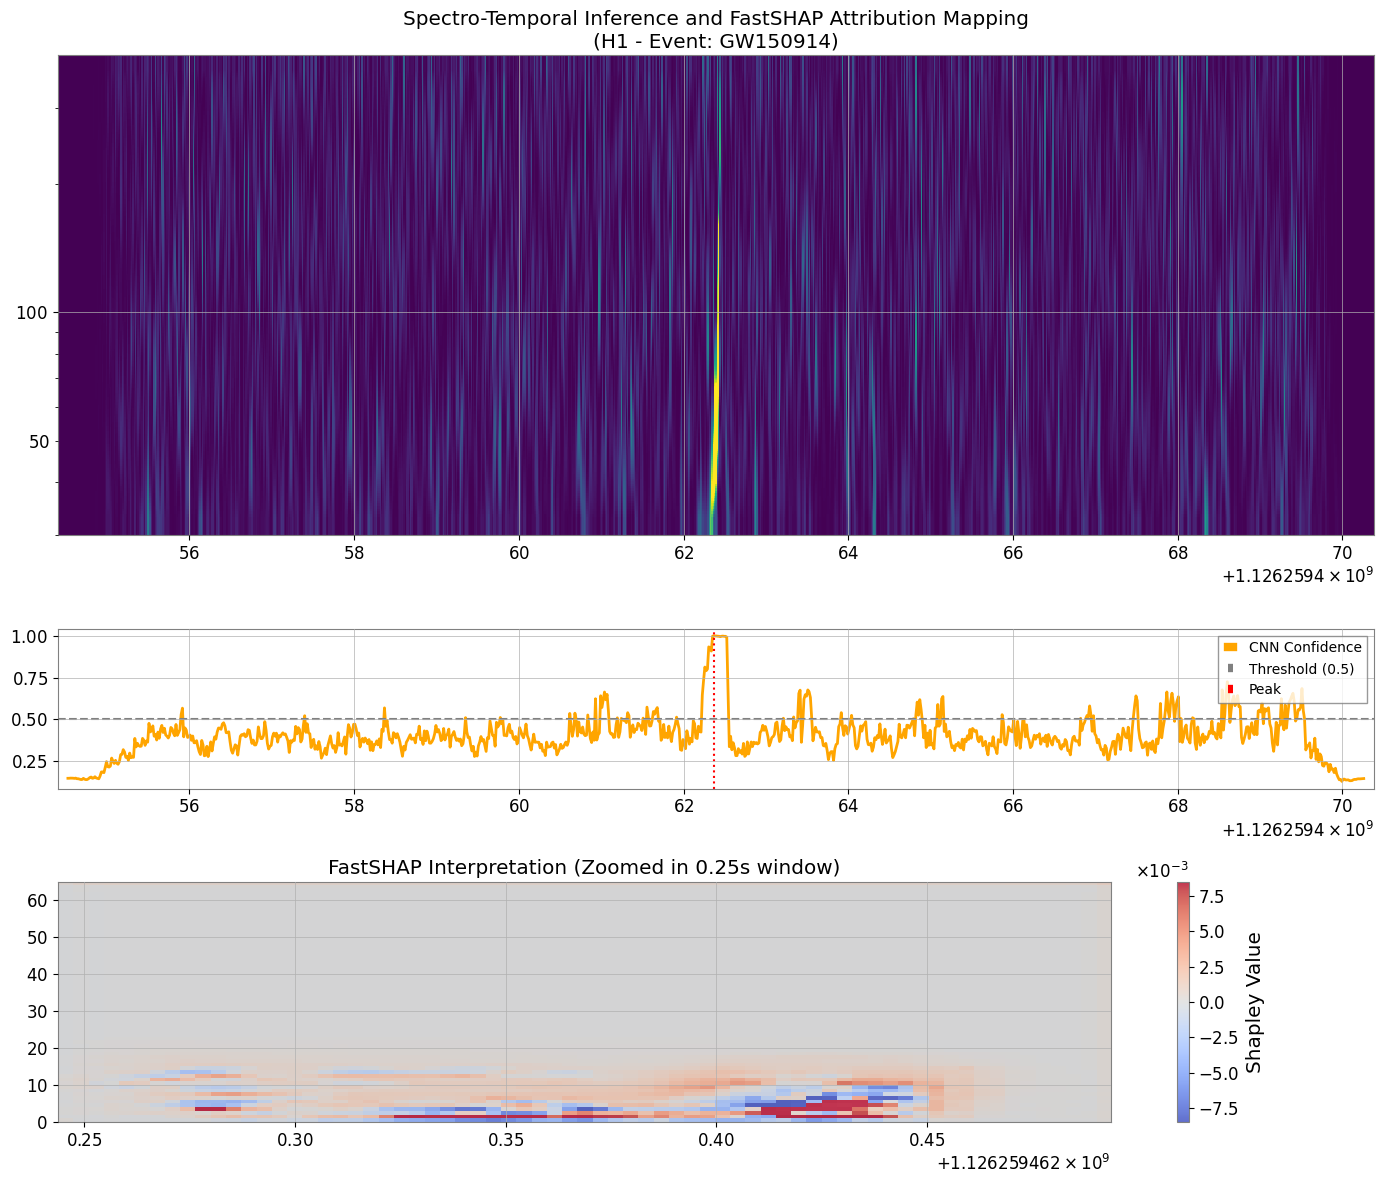

In [12]:
explain_event_pipeline(argparse.Namespace(event="GW150914", gps=None, detector="H1", duration=16.0))

Max probability: 0.8791 at 1242442967.3999023
Saved inference_GW190521_H1.svg inside generated_graphs


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  [auto-download] sent to browser: generated_graphs/inference_GW190521_H1.svg


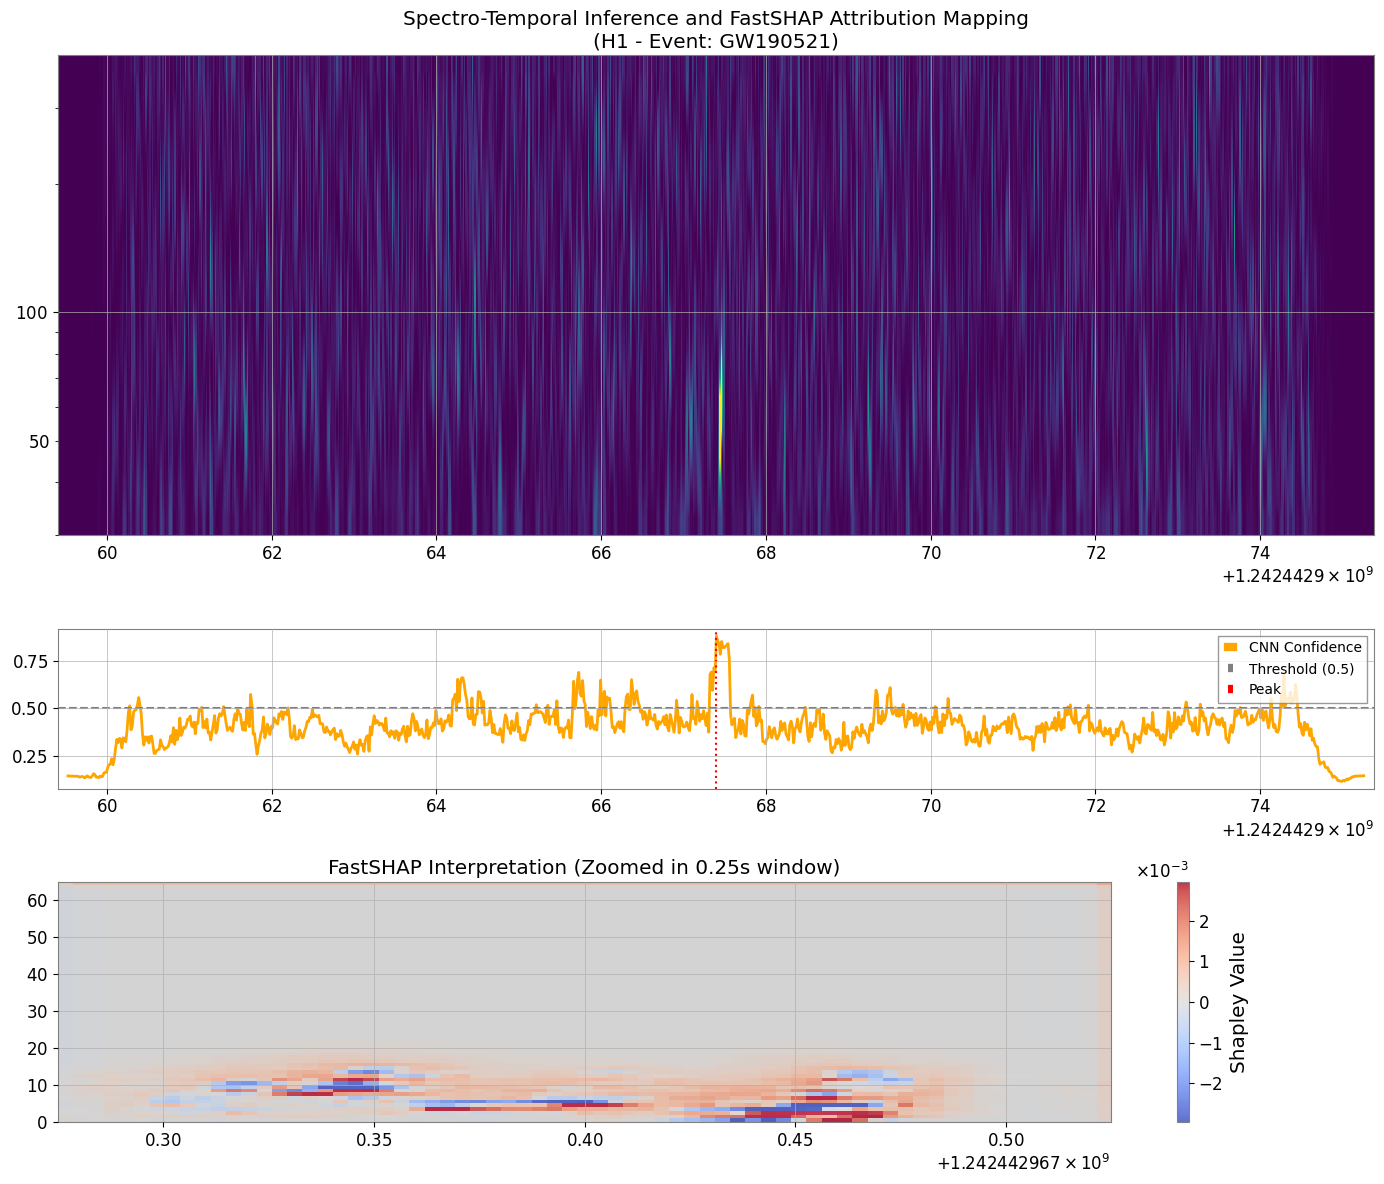

In [13]:
explain_event_pipeline(argparse.Namespace(event="GW190521", gps=None, detector="H1", duration=16.0))

Max probability: 0.9435 at 1180922494.390625
Saved inference_GW170608_H1.svg inside generated_graphs


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  [auto-download] sent to browser: generated_graphs/inference_GW170608_H1.svg


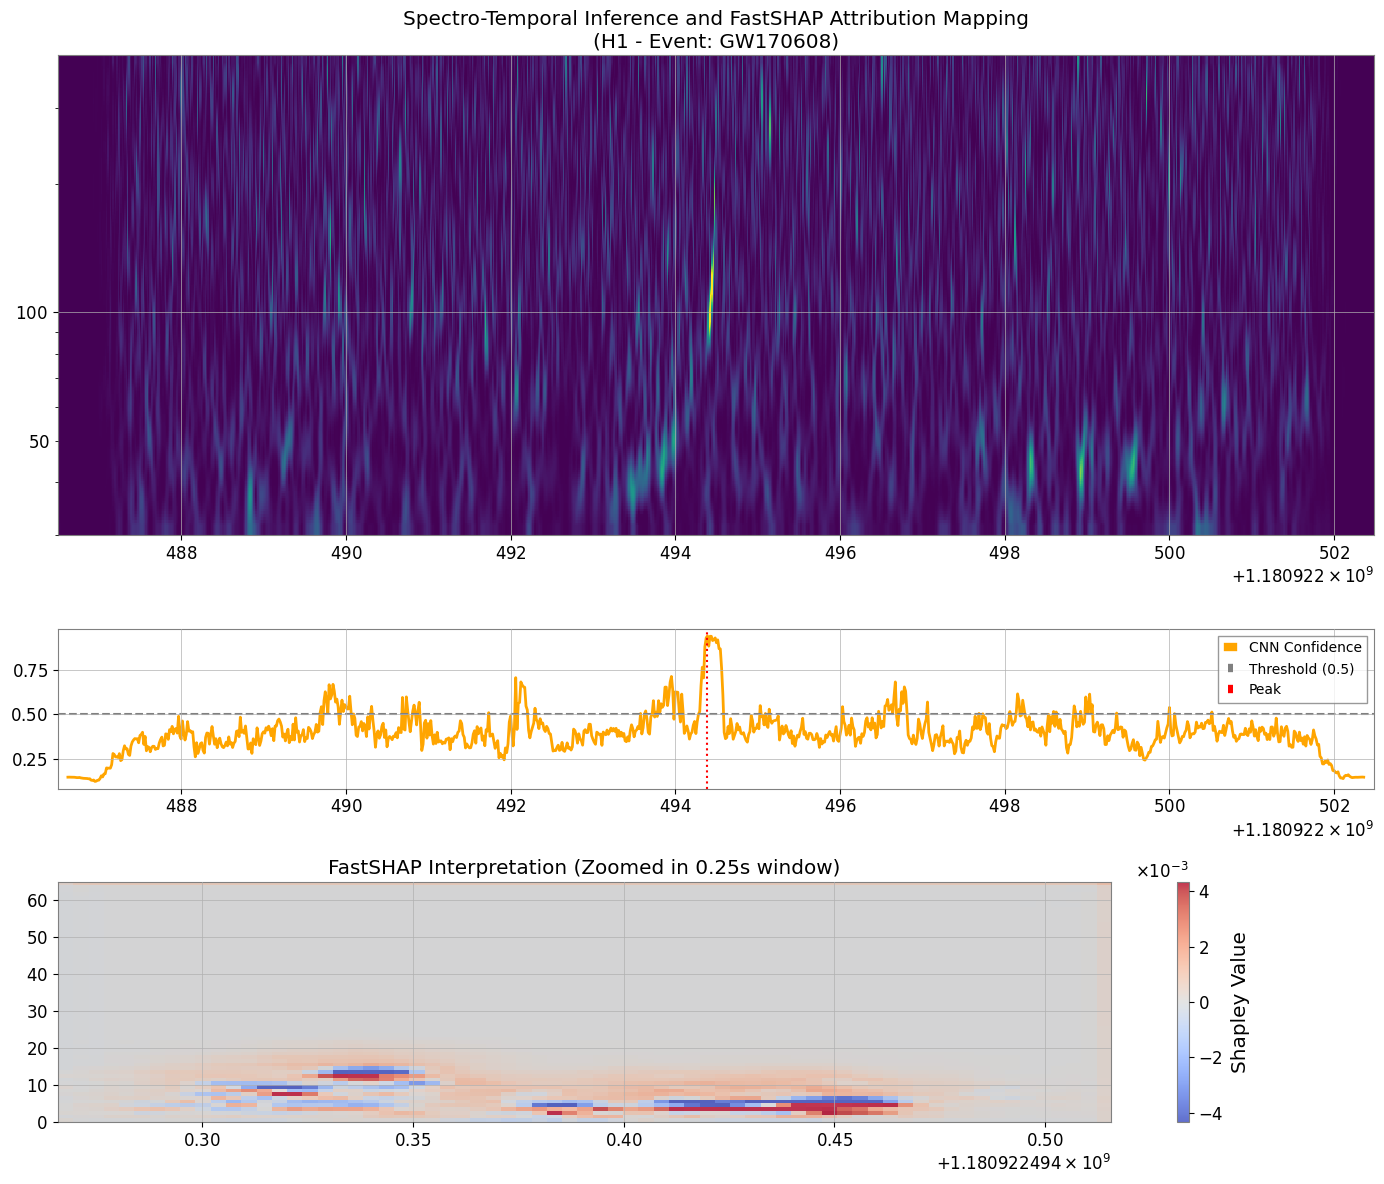

In [14]:
explain_event_pipeline(argparse.Namespace(event="GW170608", gps=None, detector="H1", duration=16.0))

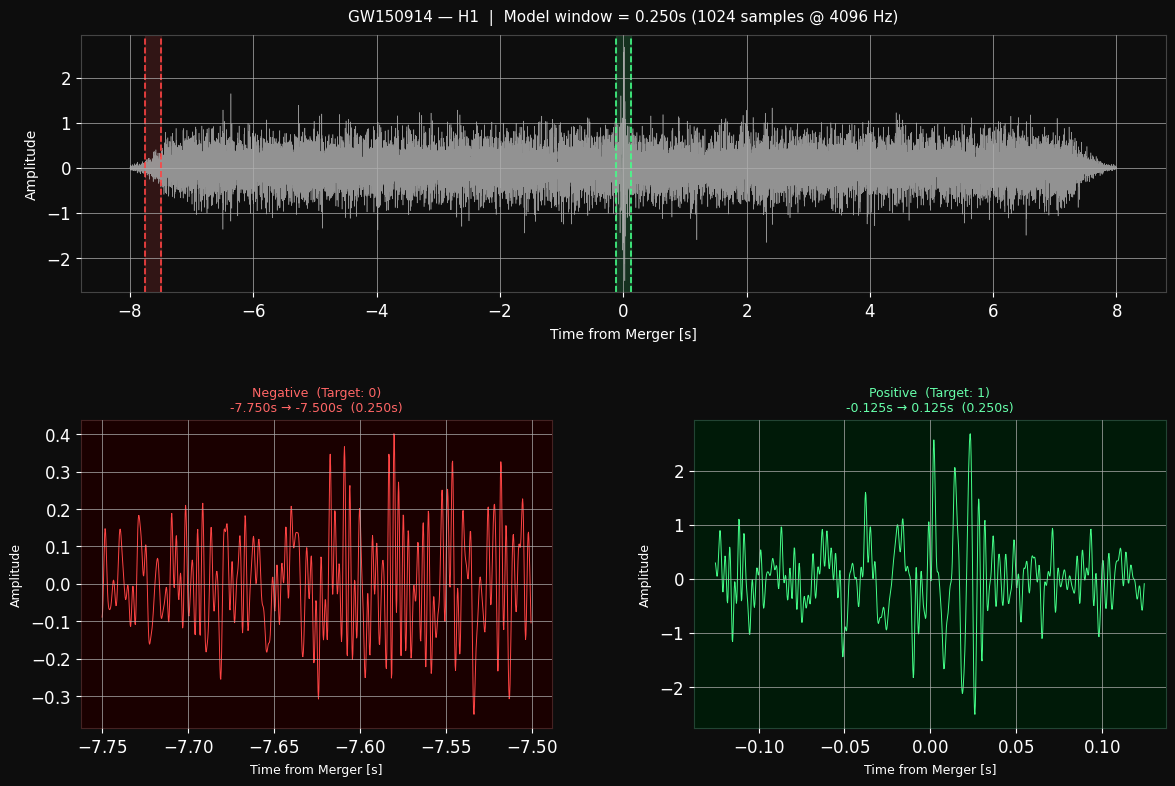

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from gwpy.timeseries import TimeSeries
from gwosc.datasets import event_gps

# ── Config ────────────────────────────────────────────────────────────────────
SAMPLE_RATE   = 4096
SEQ_LEN       = 1024
WINDOW_SECS   = SEQ_LEN / SAMPLE_RATE   # 0.25s
DURATION      = 16
BANDPASS_LOW  = 30
BANDPASS_HIGH = 400
DETECTOR      = "H1"
EVENT         = "GW150914"              # ← change only this

# ── Single fetch ──────────────────────────────────────────────────────────────
gps    = event_gps(EVENT)
strain = TimeSeries.fetch_open_data(
            DETECTOR, gps - DURATION/2, gps + DURATION/2,
            sample_rate=SAMPLE_RATE, cache=True)
strain = strain.whiten().bandpass(BANDPASS_LOW, BANDPASS_HIGH)
data   = strain.value
times  = strain.times.value - gps

# ── Slice segments from the single fetched stream ─────────────────────────────
peak_idx  = np.argmin(np.abs(times))
pos_start = peak_idx - SEQ_LEN // 2
pos_seg   = data[pos_start : pos_start + SEQ_LEN]
pos_times = times[pos_start : pos_start + SEQ_LEN]

neg_start = SEQ_LEN
neg_seg   = data[neg_start : neg_start + SEQ_LEN]
neg_times = times[neg_start : neg_start + SEQ_LEN]

# ── Plot ──────────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(14, 9), facecolor="#0d0d0d")
gs  = gridspec.GridSpec(2, 2, figure=fig,
                        height_ratios=[1, 1.2],
                        hspace=0.45, wspace=0.3)

ax_top = fig.add_subplot(gs[0, :])
ax_neg = fig.add_subplot(gs[1, 0])
ax_pos = fig.add_subplot(gs[1, 1])

# Top: full stream with highlighted windows
ax_top.plot(times, data, color="#aaaaaa", lw=0.4, alpha=0.85)
for t0, t1, col in [(neg_times[0], neg_times[-1], "#ff4444"),
                    (pos_times[0], pos_times[-1], "#44ff88")]:
    ax_top.axvspan(t0, t1, color=col, alpha=0.15)
    ax_top.axvline(t0, color=col, lw=1.2, ls="--")
    ax_top.axvline(t1, color=col, lw=1.2, ls="--")

ax_top.set_facecolor("#0d0d0d")
ax_top.set_title(
    f"{EVENT} — {DETECTOR}  |  "
    f"Model window = {WINDOW_SECS:.3f}s ({SEQ_LEN} samples @ {SAMPLE_RATE} Hz)",
    color="white", fontsize=11, pad=10)
ax_top.set_xlabel("Time from Merger [s]", color="white", fontsize=10)
ax_top.set_ylabel("Amplitude",            color="white", fontsize=10)
ax_top.tick_params(colors="white")
for sp in ax_top.spines.values(): sp.set_edgecolor("#444444")

# Bottom-left: noise segment
ax_neg.set_facecolor("#1a0000")
ax_neg.plot(neg_times, neg_seg, color="#ff4444", lw=0.7)
ax_neg.set_title(
    f"Negative  (Target: 0)\n"
    f"{neg_times[0]:.3f}s → {neg_times[-1]:.3f}s  ({WINDOW_SECS:.3f}s)",
    color="#ff6666", fontsize=9)
ax_neg.set_xlabel("Time from Merger [s]", color="white", fontsize=9)
ax_neg.set_ylabel("Amplitude",            color="white", fontsize=9)
ax_neg.tick_params(colors="white")
for sp in ax_neg.spines.values(): sp.set_edgecolor("#442222")

# Bottom-right: signal segment
ax_pos.set_facecolor("#001a08")
ax_pos.plot(pos_times, pos_seg, color="#44ff88", lw=0.7)
ax_pos.set_title(
    f"Positive  (Target: 1)\n"
    f"{pos_times[0]:.3f}s → {pos_times[-1]:.3f}s  ({WINDOW_SECS:.3f}s)",
    color="#66ffaa", fontsize=9)
ax_pos.set_xlabel("Time from Merger [s]", color="white", fontsize=9)
ax_pos.set_ylabel("Amplitude",            color="white", fontsize=9)
ax_pos.tick_params(colors="white")
for sp in ax_pos.spines.values(): sp.set_edgecolor("#224433")

plt.savefig(f"segment_viz_{EVENT}_{DETECTOR}.png",
            dpi=150, bbox_inches="tight", facecolor="#0d0d0d")
plt.show()